In [17]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-
import time
from coffea import hist, nanoevents, util
from coffea.util import load, save
import coffea.processor as processor
import awkward as ak
import numpy as np
import glob as glob
import re
import itertools
# import vector as vec
from coffea.nanoevents.methods import vector, candidate
from coffea.nanoevents import NanoAODSchema, BaseSchema
from coffea.lumi_tools import LumiMask
# for applying JECs
from coffea.lookup_tools import extractor
from coffea.jetmet_tools import FactorizedJetCorrector
from coffea.jetmet_tools import JECStack, CorrectedJetsFactory, JetCorrectionUncertainty, CorrectedMETFactory
from coffea.jetmet_tools import JetResolution, JetResolutionScaleFactor
# from jmeCorrections import JetMetCorrections
import json


import coffea.processor as processor
from coffea import hist
from coffea.analysis_tools import PackedSelection, Weights
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
from coffea.nanoevents.methods import nanoaod

NanoAODSchema.warn_missing_crossrefs = False
from optparse import OptionParser
import pickle
np.errstate(invalid='ignore', divide='ignore')
import correctionlib


def GetPUSF(IOV, nTrueInt, var='nominal'):
    fname = "../../data/pileup/UL/puWeights"+IOV+".json.gz"
    hname = {
        "2016preVFP": "Collisions16_UltraLegacy_goldenJSON",
        "2016postVFP"   : "Collisions16_UltraLegacy_goldenJSON",
        "2017"   : "Collisions17_UltraLegacy_goldenJSON",
        "2018"   : "Collisions18_UltraLegacy_goldenJSON"
    }
    evaluator = correctionlib.CorrectionSet.from_file(fname)
    return evaluator[hname[IOV]].evaluate(np.array(nTrueInt), var)
def get_data_era(events, year):
    runNMax = max(events.run)
    runNMin = min(events.run)
    if "2018" in year:

        if (runNMin >=315252) and (runNMax <=316995):
            era = "A"

        elif (runNMin >=316998) and (runNMax <=319312):
            era = "B"

        elif (runNMin >=319313) and (runNMax <=320393):
            era = "C"

        elif (runNMin >=320394) and (runNMax <=325273):
            era = "D"
       
    elif "2017" in year:
        if (runNMin >=297020) and (runNMax <=299329):
            era = "B"

        elif (runNMin >=299337) and (runNMax <=302029):
            era = "C"

        elif (runNMin >=302030) and (runNMax <=303434):
            era = "D"

        elif (runNMin >=303435) and (runNMax <=304826):
            era = "E"

        elif (runNMin >=304911) and (runNMax <=306462):
            era = "F"

        else: era = "F"
    if "2016" in year:

        if (runNMin >=272007) and (runNMax <=275376):
            era = "BCD"

        elif (runNMin >=275656) and (runNMax <=276283):
            era = "BCD"
#                         #print(era)
        elif (runNMin >=276315) and (runNMax <=276811):
            era = "BCD"

        elif (runNMin >=276831) and (runNMax <=277420) :
            era = "EF"

        elif (runNMin >=277772 and runNMax <=278807) or (runNMin in [278770, 278806, 278807]) or (runNMax in [278770, 278806, 278807] ):
            era = "EF"
        elif (runNMin >=278801 and runNMax <=278808) or (runNMax in [278769, 278806, 278807]) or (runNMax in [278769,278806, 278807]):
            era = "EF"

        elif (runNMin >=278820) and (runNMax <=280385):
            era = "G"
        elif (runNMin >=281613) and (runNMax <=284044):
            era = "H"
    return(era)
def METXYCorr_Met_MetPhi(events, year, metpt, metphi):


    #https://lathomas.web.cern.ch/lathomas/METStuff/XYCorrections/XYMETCorrection_withUL17andUL18.h
    if 'genWeight' in events.fields:
        isData = False
    else: isData = True
    dataset=events.metadata['dataset'] 
#     dataset = 'WJetsToLNu_Pt-400To600_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____1_'

    originalMet = metpt
    originalMet_phi = metpt

    npv  = events.PV.npvsGood
    mask = np.asarray(npv>100)
    npv = np.asarray(npv)
#     #print(npv)
    npv[mask==True] = 100


    if not isData:
        if (year == '2016') and ("preVFP" in dataset):
            METxcorr = -(-0.188743*npv +0.136539)
            METycorr = -(0.0127927*npv +0.117747)

        if (year == '2016') and ("postVFP" in dataset):
            METxcorr = -(-0.153497*npv -0.231751)
            METycorr = -(0.00731978*npv +0.243323)

        elif year == '2017':
            METxcorr = -(-0.300155*npv +1.90608)
            METycorr = -(0.300213*npv +-2.02232)
        elif year == '2018':
            #print("hi I am in MC metxycorr")
            #print(year)
            #print(-(0.183518*npv +0.546754))
            METxcorr = -(0.183518*npv +0.546754)
            METycorr = -(0.192263*npv +-0.42121)

    if isData:

#                 #print(runNMax, runNMin)
        if "2018" in year:
            runNMax = max(events.run)
            runNMin = min(events.run)
            if (runNMin >=315252) and (runNMax <=316995):
                era = "A"

            elif (runNMin >=316998) and (runNMax <=319312):
                era = "B"

            elif (runNMin >=319313) and (runNMax <=320393):
                era = "C"

            elif (runNMin >=320394) and (runNMax <=325273):
                era = "D"
            if "A" in era:
                METxcorr = -(0.263733*npv +-1.91115)
                METycorr = -(0.0431304*npv +-0.112043)
            elif "B" in era:
                METxcorr = -(0.400466*npv +-3.05914)
                METycorr = -(0.146125*npv +-0.533233)
            elif "C" in era:
                METxcorr = -(0.430911*npv +-1.42865)
                METycorr = -(0.0620083*npv +-1.46021)
            elif "D" in era:
                METxcorr = -(0.457327*npv +-1.56856)
                METycorr = -(0.0684071*npv +-0.928372)


        if "2017" in year:

            runNMax = max(events.run)
            runNMin = min(events.run)
            if (runNMin >=297020) and (runNMax <=299329):
                era = "B"

            elif (runNMin >=299337) and (runNMax <=302029):
                era = "C"

            elif (runNMin >=302030) and (runNMax <=303434):
                era = "D"

            elif (runNMin >=303435) and (runNMax <=304826):
                era = "E"

            elif (runNMin >=304911) and (runNMax <=306462):
                era = "F"

            else: era = "X"
            if "E" in era:
                METxcorr = -(-0.162472*npv +0.176329)
                METycorr = -(0.138076*npv +-0.250239)
            elif "B" in era:
                METxcorr = -(-0.211161*npv +0.419333)
                METycorr = -(0.251789*npv +-1.28089)
            elif "C" in era:
                METxcorr = -(-0.185184*npv +-0.164009)
                METycorr = -(0.200941*npv +-0.56853)
            elif "D" in era:
                METxcorr = -(-0.201606*npv +0.426502)
                METycorr = -(0.188208*npv +-0.58313)
            elif "F" in era:
                METxcorr = -(-0.210639*npv +0.72934)
                METycorr = -(0.198626*npv +1.028)
            elif "X" in era:
                METxcorr = np.zeros(len(events))
                METycorr = np.zeros(len(events))
        if "2016" in year:
            runNMax = max(events.run)
            runNMin = min(events.run)

            if (runNMin >=272007) and (runNMax <=275376):
                era = "B"
                #print(era)
            elif (runNMin >=275656) and (runNMax <=276283):
                era = "C"
                #print('runNMax', runNMax, 'runMin', runNMin, ' era:', era)
#                         #print(era)
            elif (runNMin >=276315) and (runNMax <=276811):
                era = "D"
                #print(era)
            elif (runNMin >=276831) and (runNMax <=277420) :
                era = "E"
                #print(era)
            elif (runNMin >=277772 and runNMax <=278807) or (runNMin in [278770, 278806, 278807]) or (runNMax in [278770, 278806, 278807] ):
                era = "F"
#                  https://twiki.cern.ch/twiki/bin/viewauth/CMS/PdmVDatasetsUL2016
                #print(era)
            elif (runNMin >=278801 and runNMax <=278808) or (runNMax in [278769, 278806, 278807]) or (runNMax in [278769,278806, 278807]):
                era = "F_late"
                #print(era)
            elif (runNMin >=278820) and (runNMax <=280385):
                era = "G"
                #print(era)
            elif (runNMin >=281613) and (runNMax <=284044):
                era = "H"
                #print(era)

            if "B" in era:
                METxcorr = -(-0.0214894*npv +-0.188255)
                METycorr = -(0.0876624*npv +0.812885)
            elif "C" in era:
                METxcorr = -(-0.032209*npv +0.067288)
                METycorr = -(0.113917*npv +0.743906)
            elif "D" in era:
                METxcorr = -(-0.0293663*npv +0.21106)
                METycorr = -(0.11331*npv +0.815787)
            elif "E" in era:
                METxcorr = -(-0.0132046*npv +0.20073)
                METycorr = -(0.134809*npv +0.679068)
            elif "F" in era:
                METxcorr = -(-0.0543566*npv +0.816597)
                METycorr = -(0.114225*npv +1.17266)
            elif "F_late" in era:
                METxcorr = -(0.134616*npv +-0.89965)
                METycorr = -(0.0397736*npv +1.0385)
            elif "G" in era:
                METxcorr = -(0.121809*npv +-0.584893)
                METycorr = -(0.0558974*npv +0.891234)
            elif "H" in era:
                METxcorr = -(0.0868828*npv +-0.703489)
                METycorr = -(0.0888774*npv +0.902632)

    CorrectedMET_x = np.multiply(originalMet,np.cos(originalMet_phi))+ (np.array(METxcorr))
    CorrectedMET_y = np.multiply(originalMet,np.sin(originalMet_phi))+ (np.array(METycorr))
#             #print(CorrectedMET_x/CorrectedMET_y)
#   double CorrectedMET_x = uncormet *cos( uncormet_phi)+METxcorr;
#   double CorrectedMET_y = uncormet *sin( uncormet_phi)+METycorr;
    CorrectedMET = np.sqrt((CorrectedMET_x)**2+(CorrectedMET_y)**2)
    CorrectedMETPhi = np.zeros(len(events))



    
    
    mask1 = (CorrectedMET_x ==0 )& (CorrectedMET_y > 0)
    CorrectedMETPhi[mask1==True] = np.pi

    mask2 = (CorrectedMET_x ==0 )& (CorrectedMET_y < 0)
    CorrectedMETPhi[mask2==True] = -np.pi

    mask3 = (CorrectedMET_x <0 )& (CorrectedMET_y > 0)
    CorrectedMETPhi[mask3==True] = (np.arctan(CorrectedMET_y/CorrectedMET_x) + np.pi )[mask3==True] 

    mask4 = (CorrectedMET_x <0 )& (CorrectedMET_y < 0)
    CorrectedMETPhi[mask4==True] = (np.arctan(CorrectedMET_y/CorrectedMET_x) - np.pi )[mask4==True]

    mask5 = (CorrectedMET_x >0 )
    CorrectedMETPhi[mask5==True] = (np.arctan(CorrectedMET_y/CorrectedMET_x))[mask5==True]   

    mask6 = (~mask1 & ~mask2 & ~mask3 & ~mask4 & ~mask5) 
    CorrectedMETPhi[mask6==True] = 0

    return (CorrectedMET, CorrectedMETPhi)

class AnalysisProcessor(processor.ProcessorABC):
    
    
    lumis = {  # Values from https://twiki.cern.ch/twiki/bin/viewauth/CMS/PdmVAnalysisSummaryTable
        '2016': {'preVFP':19.52,'postVFP':16.81},
                 #postVFP
        '2017': 40.66,
        '2018': 59.74
    }

    
    met_filter_flags = {

        '2016': ['goodVertices',
                 'globalSuperTightHalo2016Filter',
                 'HBHENoiseFilter',
                 'HBHENoiseIsoFilter',
                 'EcalDeadCellTriggerPrimitiveFilter',
                 'BadPFMuonFilter',
                 'BadPFMuonDzFilter',
#                  'eeBadScFilter',
                 
                 ],

        '2017': ['goodVertices',
                 'globalSuperTightHalo2016Filter',
                 'HBHENoiseFilter',
                 'HBHENoiseIsoFilter',
                 'EcalDeadCellTriggerPrimitiveFilter',
                 'BadPFMuonFilter',
                 'ecalBadCalibFilter',
#                  'eeBadScFilter',
                 'BadPFMuonDzFilter',
#                  'hfNoisyHitsFilter'
                 ],

        '2018': ['goodVertices',
                 'globalSuperTightHalo2016Filter',
                 'HBHENoiseFilter',
                 'HBHENoiseIsoFilter',
                 'EcalDeadCellTriggerPrimitiveFilter',
                 'BadPFMuonFilter',
                 'ecalBadCalibFilter',
#                  'eeBadScFilter',
                 'BadPFMuonDzFilter',
#                  'hfNoisyHitsFilter'
                 ]
    }

    def __init__(self, year, xsec, corrections, ids, common, vfp):
        ak.behavior.update(nanoaod.behavior)
        self._year = year
        if self._year == "2016":
            self._lumi = 1000.*float(AnalysisProcessor.lumis[year][vfp])
        else:   
            self._lumi = 1000.*float(AnalysisProcessor.lumis[year])

        self._xsec = xsec
        
        self._samples = {
            'sre':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD', 'SingleElectron','EGamma',
                   'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
            'srm':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleMuon',
                    'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
            'ttbare':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleElectron','EGamma',
                     'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
            'ttbarm':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleMuon',
                     'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
            'wjete':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD', 'SingleElectron','EGamma',
                    'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
            'wjetm':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleMuon',
                    'Mphi-1995_Mchi-1000',
                    'Mphi-2000_Mchi-1500',
                    'Mphi-2000_Mchi-500'),
        }
        
        self._singleelectron_triggers = {  # 2017 and 2018 from monojet, applying dedicated trigger weights
            '2016': [
                'Ele27_WPTight_Gsf',
#                 'Ele105_CaloIdVT_GsfTrkIdT'
                'Ele115_CaloIdVT_GsfTrkIdT'
                'Ele50_CaloIdVT_GsfTrkIdT_PFJet165'
            ],
            '2017': [
                'Ele35_WPTight_Gsf',
                'Ele115_CaloIdVT_GsfTrkIdT',
                'Photon200'
            ],
            '2018': [
                'Ele32_WPTight_Gsf',
                'Ele115_CaloIdVT_GsfTrkIdT',
                'Photon200','Ele50_CaloIdVT_GsfTrkIdT_PFJet165'
            ]
        }
        
        self._singlemuon_triggers = {
            '2016': [
                'IsoMu24',
                'IsoTkMu24',
                'Mu50',
                'TkMu50'

            ],
            '2017':
                [
                'IsoMu27',
                'Mu50',
                'OldMu100',
                'TkMu100'
            ],
            '2018':
                [
                'IsoMu24',
                'Mu50',
                'OldMu100',
                'TkMu100'
            ]
        }
        

        self._jec = {

            '2016':  
                    {
                        'no_apv':
                        ['Summer19UL16_V7_MC_L1FastJet_AK4PFchs',
                        'Summer19UL16_V7_MC_L2L3Residual_AK4PFchs',
                        'Summer19UL16_V7_MC_L2Relative_AK4PFchs',
                        'Summer19UL16_V7_MC_L2Residual_AK4PFchs',
                        'Summer19UL16_V7_MC_L3Absolute_AK4PFchs',

                        ],
                    
                        'apv':
                        ['Summer19UL16APV_V7_MC_L1FastJet_AK4PFchs',
                        'Summer19UL16APV_V7_MC_L2L3Residual_AK4PFchs',
                        'Summer19UL16APV_V7_MC_L2Relative_AK4PFchs',
                        'Summer19UL16APV_V7_MC_L2Residual_AK4PFchs',
                        'Summer19UL16APV_V7_MC_L3Absolute_AK4PFchs',

                        ]
                    },


            '2017': [
                'Summer19UL17_V5_MC_L1FastJet_AK4PFchs',
                'Summer19UL17_V5_MC_L2L3Residual_AK4PFchs',
                'Summer19UL17_V5_MC_L2Relative_AK4PFchs',
                'Summer19UL17_V5_MC_L2Residual_AK4PFchs',
                'Summer19UL17_V5_MC_L3Absolute_AK4PFchs',

                
            ],

            '2018': [
                'Summer19UL18_V5_MC_L1FastJet_AK4PFchs',
                'Summer19UL18_V5_MC_L2Relative_AK4PFchs',
                'Summer19UL18_V5_MC_L2L3Residual_AK4PFchs',
                'Summer19UL18_V5_MC_L3Absolute_AK4PFchs',
                

            ]
        }
        
        self._junc = {

            '2016': 
            {
            'no_apv': ['Summer19UL16_V7_MC_Uncertainty_AK4PFchs',
                      ],
                     'apv': ['Summer19UL16APV_V7_MC_Uncertainty_AK4PFchs',
                            ]},

            

            '2017': [
                'Summer19UL17_V5_MC_Uncertainty_AK4PFchs',
            ],

            '2018': [
                'Summer19UL18_V5_MC_Uncertainty_AK4PFchs',
            ],
        }
        
        self._jr = {

            '2016': 
            {'apv': ['Summer20UL16APV_JRV3_MC_PtResolution_AK4PFchs',
                    ],
                     'no_apv': ['Summer20UL16_JRV3_MC_PtResolution_AK4PFchs',
                               ]},


            '2017': [
                'Summer19UL17_JRV2_MC_PtResolution_AK4PFchs',
            ],

            '2018': [
                'Summer19UL18_JRV2_MC_PtResolution_AK4PFchs',
            ]
        }
        
        self._jersf = {

            '2016': 
            {'no_apv':['Summer20UL16_JRV3_MC_SF_AK4PFchs',
                      ],
                     'apv':['Summer20UL16APV_JRV3_MC_SF_AK4PFchs',
                           ]},

            

            '2017': [
                'Summer19UL17_JRV2_MC_SF_AK4PFchs',
            ],

            '2018': [
                'Summer19UL18_JRV2_MC_SF_AK4PFchs',
            ]
        }
        
        self._golden_json_path = {
        '2016': '../../data/golden_txt/Cert_271036-284044_13TeV_Legacy2016_Collisions16_JSON.txt',
        '2017': '../../data/golden_txt/Cert_294927-306462_13TeV_UL2017_Collisions17_GoldenJSON.txt',
        '2018': '../../data/golden_txt/Cert_314472-325175_13TeV_Legacy2018_Collisions18_JSON.txt',
}
        self._corrections = corrections
        self._ids = ids
        self._common = common

        self._accumulator = processor.dict_accumulator({
            'sumw': hist.Hist(
                'sumw',
                hist.Cat('dataset', 'Dataset'),
                hist.Bin('sumw', 'Weight value', [0.])),
            
            'template': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('npvs', 'NPVS', 99, 0, 99),
                hist.Bin('mT_corrected', '$m_{T}$ [GeV] Corrected', [100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500])),
            
             'mT_corrected': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mT_corrected', '$m_{T} XY \Phi Corrected$ [GeV]',[100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500])),
#             "EventCount": processor.value_accumulator(int),
            'cutflow': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
#                 hist.Bin('cut', 'Cut index', 11, 0, 11),
                hist.Bin('cut', 'Cut index', [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17])),
            'eT_miss_corrected': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('eT_miss_corrected', '$E^T_{miss} Corrected$[GeV]', 20, 0, 600)),
            'ele_pT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ele_pT', 'Tight electron $p_{T}$ [GeV]', 10, 0, 200)),
            'leading_mu_pT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('leading_mu_pT', 'Leading Muon $p_{T}$ [GeV]', 10, 0, 200)),
            'mu_pT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mu_pT', 'Tight Muon $p_{T}$ [GeV]', 10, 0, 200)),
            'j1pt': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('j1pt','AK4 Leading Jet Pt',[30.0, 60.0, 90.0, 120.0, 150.0, 180.0, 210.0, 250.0, 280.0, 310.0, 340.0, 370.0, 400.0, 430.0, 470.0, 510.0, 550.0, 590.0, 640.0, 690.0, 740.0, 790.0, 840.0, 900.0, 960.0, 1020.0, 1090.0, 1160.0, 1250.0])
            ),
            'j1eta': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('j1eta','AK4 Leading Jet Eta',35,-3.5,3.5)),
            
            'j1phi': hist.Hist(
                'Events', 
                hist.Cat('dataset', 'Dataset'), 
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('j1phi','AK4 Leading Jet Phi',35,-3.5,3.5)),

            'dphi_e_etmiss': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('dphi_e_etmiss', '$\Delta\phi (e, E^T_{miss} )$', 30, 0, 3.5)),
            
            'dphi_mu_etmiss': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('dphi_mu_etmiss','$\Delta\phi (\mu, E^T_{miss} )$', 30, 0, 3.5)),
            
            'ndflvL': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ndflvL', 'AK4 Number of deepFlavor Loose Jets', 6, -0.5, 5.5)),
            'ndflvM': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ndflvM', 'AK4 Number of deepFlavor Medium Jets', 6, -0.5, 5.5)),
            'njets': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('njets', 'AK4 Number of Jets', 7, -0.5, 6.5)),

            'ndcsvM': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ndcsvM', 'AK4 Number of deepCSV Medium Jets', 6, -0.5, 5.5)),
            
            'dphi_Corr_Met_LJ': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('dphi_Corr_Met_LJ', '$\Delta \Phi (E^T_{miss corr}, Leading Jet)$', 30, 0, 3.5)),
            'dr_e_lj': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('dr_e_lj', '$\Delta r (Leading e, Leading Jet)$', 30, 0, 5.0)),
            'dr_mu_lj': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('dr_mu_lj', '$\Delta r (Leading \mu, Leading Jet)$', 30, 0, 5.0)),
            'ele_eta': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ele_eta', 'Leading Electron Eta', 48, -2.4, 2.4)),
            'mu_eta': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mu_eta', 'Leading Muon Eta', 48, -2.4, 2.4)),
            'ele_phi': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ele_phi', 'Leading Electron Phi', 64, -3.2, 3.2)),
            
            'ele_phi_loose': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('ele_phi_loose', 'Loose Electron Phi', 64, -3.2, 3.2)),

            'eT_miss_corrected_phi': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('eT_miss_corrected_phi','MET phi Corrected',35,-3.5,3.5)),
            'mu_phi': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mu_phi', 'Leading Muon Phi', 64, -3.2, 3.2)),
            'npvs': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('npvs', 'NPVS', 99, 0, 99)),
 
        })

    @property
    def accumulator(self):
        return self._accumulator



    def process(self, events):
        ## Here we pre-compute a few common variables that we will re-use later and add them to the events object

        # Temporary patch so we can add photon and lepton four vectors. Not needed for newer versions of NanoAOD
        events["Photon", "charge"] = 0
        # Calculate charged hadron isolation for photons
        events["Photon", "chIso"] = (events.Photon.pfRelIso03_chg) * (events.Photon.pt)
        self.isMC ='genWeight' in events.fields
        if self.isMC:
            output = self.accumulator.identity()
#             shift_systs = [  , "METunclUp", "METunclDown"]
            shift_systs = [None, "JERUp", "JERDown","JESUp", "JESDown", 
                           "puUp", "puDown", "L1PrefireUp", "L1PrefireDown"]
            for _syst in shift_systs:
                print("shift sys", _syst)
                output += self.process_shift(events, _syst)
        else:
            # data doesn't need each systematic shift to be processed
            output = self.process_shift(events, "nominal")

        # only add events up once
#         output["EventCount"] += len(events)
        return output
            
    def process_shift(self, events, shift_syst=None):
            
        dataset = events.metadata['dataset']
        isData = 'genWeight' not in events.fields
        isMC = 'genWeight' in events.fields
        selection = processor.PackedSelection()
        hout = self.accumulator.identity()
            
        selected_regions = []
        for region, samples in self._samples.items():
            for sample in samples:
                if sample not in dataset:
                    continue
                selected_regions.append(region)
            
        ###
        # Getting corrections, ids from .coffea files
        ###
        if ("preVFP" in dataset) and (self._year == '2016'):
            get_ele_loose_id_sf = self._corrections['get_ele_tight_id_sf_preVFP'][self._year]
            get_ele_tight_id_sf = self._corrections['get_ele_tight_id_sf_preVFP'][self._year]
            
            get_ele_reco_sf = self._corrections['get_ele_reco_sf_preVFP_above20'][self._year]
            get_ele_reco_err = self._corrections['get_ele_reco_err_preVFP_above20'][self._year]
            
            get_ele_reco_lowet_sf = self._corrections['get_ele_reco_sf_preVFP_below20'][self._year]
            get_ele_reco_lowet_err = self._corrections['get_ele_reco_err_preVFP_below20'][self._year]
            
            get_mu_tight_id_sf = self._corrections['get_mu_tight_id_sf_preVFP'][self._year]
            get_mu_loose_id_sf = self._corrections['get_mu_loose_id_sf_preVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_preVFP'][self._year]
            get_mu_loose_err_sf = self._corrections['get_mu_loose_id_err_preVFP'][self._year]            
            
            
            get_mu_tight_iso_sf = self._corrections['get_mu_tight_iso_sf_preVFP'][self._year]
            get_mu_loose_iso_sf = self._corrections['get_mu_loose_iso_sf_preVFP'][self._year]
            get_mu_tight_iso_err = self._corrections['get_mu_tight_iso_err_preVFP'][self._year]
            get_mu_loose_iso_err = self._corrections['get_mu_loose_iso_err_preVFP'][self._year]            

            
            get_mu_trig_weight = self._corrections['get_mu_trig_weight_preVFP'][self._year]
            get_mu_trig_err = self._corrections['get_mu_trig_err_preVFP'][self._year]
            get_ele_loose_id_err = self._corrections['get_ele_loose_id_err_preVFP'][self._year]
            get_ele_tight_id_err = self._corrections['get_ele_tight_id_err_preVFP'][self._year]
            get_mu_loose_id_err = self._corrections['get_mu_loose_id_err_preVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_preVFP'][self._year]
            
            get_deepflav_weight = self._corrections['get_btag_weight_preVFP']['deepflav'][self._year]
            
            get_pu_nom_weight = self._corrections['get_pu_nom_weight_preVFP'][self._year]
            get_pu_up_weight = self._corrections['get_pu_up_weight_preVFP'][self._year]
            get_pu_down_weight = self._corrections['get_pu_down_weight_preVFP'][self._year]
        elif ("postVFP" in dataset) and (self._year == '2016'):
            get_ele_loose_id_sf = self._corrections['get_ele_tight_id_sf_postVFP'][self._year]
            get_ele_tight_id_sf = self._corrections['get_ele_tight_id_sf_postVFP'][self._year]
            
            get_ele_reco_sf = self._corrections['get_ele_reco_sf_postVFP_above20'][self._year]
            get_ele_reco_err = self._corrections['get_ele_reco_err_postVFP_above20'][self._year]
            
            get_ele_reco_lowet_sf = self._corrections['get_ele_reco_sf_postVFP_below20'][self._year]
            get_ele_reco_lowet_err = self._corrections['get_ele_reco_err_postVFP_below20'][self._year]
            
            
            get_mu_tight_id_sf = self._corrections['get_mu_tight_id_sf_postVFP'][self._year]
            get_mu_loose_id_sf = self._corrections['get_mu_loose_id_sf_postVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_postVFP'][self._year]
            get_mu_loose_id_err = self._corrections['get_mu_loose_id_err_postVFP'][self._year]            
            
            get_mu_tight_iso_sf = self._corrections['get_mu_tight_iso_sf_postVFP'][self._year]
            get_mu_loose_iso_sf = self._corrections['get_mu_loose_iso_sf_postVFP'][self._year]
            get_mu_tight_iso_err = self._corrections['get_mu_tight_iso_err_postVFP'][self._year]
            get_mu_loose_iso_err = self._corrections['get_mu_loose_iso_err_postVFP'][self._year]
            
            
            get_mu_trig_weight = self._corrections['get_mu_trig_weight_postVFP'][self._year]
            get_mu_trig_err = self._corrections['get_mu_trig_err_postVFP'][self._year]
            get_ele_loose_id_err = self._corrections['get_ele_loose_id_err_postVFP'][self._year]
            get_ele_tight_id_err = self._corrections['get_ele_tight_id_err_postVFP'][self._year]
            get_mu_loose_id_err = self._corrections['get_mu_loose_id_err_postVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_postVFP'][self._year]
            
            get_deepflav_weight = self._corrections['get_btag_weight_postVFP']['deepflav'][self._year]
            get_pu_nom_weight = self._corrections['get_pu_nom_weight_postVFP'][self._year]
            get_pu_up_weight = self._corrections['get_pu_up_weight_postVFP'][self._year]
            get_pu_down_weight = self._corrections['get_pu_down_weight_postVFP'][self._year]
        else:
#             #print("hi")
            get_ele_loose_id_sf = self._corrections['get_ele_tight_id_sf_postVFP'][self._year]
            get_ele_tight_id_sf = self._corrections['get_ele_tight_id_sf_postVFP'][self._year]
            
            get_ele_reco_sf = self._corrections['get_ele_reco_sf_postVFP_above20'][self._year]
            get_ele_reco_err = self._corrections['get_ele_reco_err_postVFP_above20'][self._year]
            
            get_ele_reco_lowet_sf = self._corrections['get_ele_reco_sf_postVFP_below20'][self._year]
            get_ele_reco_lowet_err = self._corrections['get_ele_reco_err_postVFP_below20'][self._year]
            
            
            get_mu_tight_id_sf = self._corrections['get_mu_tight_id_sf_postVFP'][self._year]
            get_mu_loose_id_sf = self._corrections['get_mu_loose_id_sf_postVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_postVFP'][self._year]
            get_mu_loose_id_err = self._corrections['get_mu_loose_id_err_postVFP'][self._year]            
            
            get_mu_tight_iso_sf = self._corrections['get_mu_tight_iso_sf_postVFP'][self._year]
            get_mu_loose_iso_sf = self._corrections['get_mu_loose_iso_sf_postVFP'][self._year]
            get_mu_tight_iso_err = self._corrections['get_mu_tight_iso_err_postVFP'][self._year]
            get_mu_loose_iso_err = self._corrections['get_mu_loose_iso_err_postVFP'][self._year]
            
            
            get_mu_trig_weight = self._corrections['get_mu_trig_weight_postVFP'][self._year]
            get_mu_trig_err = self._corrections['get_mu_trig_err_postVFP'][self._year]
            get_ele_loose_id_err = self._corrections['get_ele_loose_id_err_postVFP'][self._year]
            get_ele_tight_id_err = self._corrections['get_ele_tight_id_err_postVFP'][self._year]
            get_mu_loose_id_err = self._corrections['get_mu_loose_id_err_postVFP'][self._year]
            get_mu_tight_id_err = self._corrections['get_mu_tight_id_err_postVFP'][self._year]
            
            get_deepflav_weight = self._corrections['get_btag_weight_postVFP']['deepflav'][self._year]
            get_pu_nom_weight = self._corrections['get_pu_nom_weight_postVFP'][self._year]
            get_pu_up_weight = self._corrections['get_pu_up_weight_preVFP'][self._year]
            get_pu_down_weight = self._corrections['get_pu_down_weight_preVFP'][self._year]
            
            
        get_ttbar_weight = self._corrections['get_ttbar_weight']
        get_nnlo_nlo_weight = self._corrections['get_nnlo_nlo_weight'][self._year]
        get_nlo_qcd_weight = self._corrections['get_nlo_qcd_weight'][self._year]
        get_nlo_ewk_weight = self._corrections['get_nlo_ewk_weight'][self._year]
#         get_pu_weight = self._corrections['get_pu_weight'][self._year]
        

        get_ele_trig_weight = self._corrections['get_ele_trig_weight'][self._year]
        get_ele_trig_err    = self._corrections['get_ele_trig_err'][self._year]
        get_pho_tight_id_sf = self._corrections['get_pho_tight_id_sf'][self._year]
        get_pho_csev_sf = self._corrections['get_pho_csev_sf'][self._year]
        get_ecal_bad_calib = self._corrections['get_ecal_bad_calib']

        Jetevaluator = self._corrections['Jetevaluator']
            
        isLooseElectron = self._ids['isLooseElectron']
        isTightElectron = self._ids['isTightElectron']
        isLooseMuon = self._ids['isLooseMuon']
        isTightMuon = self._ids['isTightMuon']
        isLooseTau = self._ids['isLooseTau']
        isLoosePhoton = self._ids['isLoosePhoton']
        isTightPhoton = self._ids['isTightPhoton']
        isGoodJet = self._ids['isGoodJet']
        isHEMJet = self._ids['isHEMJet']

        match = self._common['match']
        # to calculate photon trigger efficiency
        sigmoid = self._common['sigmoid']
        deepflavWPs = self._common['btagWPs']['deepflav'][self._year]
        deepcsvWPs = self._common['btagWPs']['deepcsv'][self._year]
            
        ###
        # Derive jet corrector for JEC/JER
        ### Not taking JEC because they have already been applied
        jec_names = []
        j = events.Jet
        met = events.MET

        if isMC:
            met["T"] = ak.zip({"pt": met.pt, "phi": met.phi}, 
                              with_name="PolarTwoVector", 
                              behavior=vector.behavior)
            j["T"] = ak.zip({"pt": j.pt, "phi": j.phi}, 
                      with_name="PolarTwoVector", 
                      behavior=vector.behavior)
            j['p4'] = ak.zip({
            "pt": j.pt,
            "eta": j.eta,
            "phi": j.phi,
            "mass": j.mass},
            with_name="PtEtaPhiMLorentzVector",
            )
            if (self._year == '2016'):
                if ("preVFP" in dataset):
    #                 #print(self._jr[self._year]['apv'][0])
                    list_of_jec = self._jec[self._year]['apv']
                    list_of_jr = self._jr[self._year]['apv']
                    list_of_junc = self._junc[self._year]['apv']
                    list_of_jersf = self._jersf[self._year]['apv']
                else: 
                    list_of_jec = self._jec[self._year]['no_apv']
                    list_of_jr =self ._jr[self._year]['no_apv']
                    list_of_junc =self ._junc[self._year]['no_apv']
                    list_of_jersf = self._jersf[self._year]['no_apv']

                for name in list_of_jec:
                    jec_names.append(name)
                for name in list_of_jr:
                    jec_names.append(name)
                for name in list_of_junc:
                    jec_names.append(name)    
                for name in list_of_jersf:
                    jec_names.append(name)                
            else:
                for name in self._jec[self._year]:
                    jec_names.append(name)                 
                for name in self._jr[self._year]:
                    jec_names.append(name)    
                for name in self._jersf[self._year]:
                    jec_names.append(name)
                for name in self._junc[self._year]:
                    jec_names.append(name)
            #print("afer____")
            #print(jec_names)
            jec_inputs = {name: Jetevaluator[name] for name in jec_names}
            jec_stack = JECStack(jec_inputs)
            jec_inputs_nojer = {name: Jetevaluator[name] for name in jec_names if "JRV" not in name }
            jec_stack_nojer = JECStack(jec_inputs_nojer)
            
#             import sys
#             print(jec_inputs_nojer)
#             sys.exit(0)

            jec_name_map = jec_stack.blank_name_map
            jec_name_map['JetPt'] = 'pt'
            jec_name_map['JetEta'] = 'eta'
            jec_name_map['JetPhi'] = 'phi'
            jec_name_map['JetMass'] = 'mass'
            jec_name_map['Rho'] = 'rho'
            jec_name_map['JetA'] = 'area'
            jec_name_map['ptGenJet'] = 'pt_gen'
            jec_name_map['ptRaw'] = 'pt_raw'
            jec_name_map['massRaw'] = 'mass_raw'
            jec_name_map['METpt'] = 'pt'
            jec_name_map['METphi'] = 'phi'
            jec_name_map['UnClusteredEnergyDeltaX'] = 'MetUnclustEnUpDeltaX'
            jec_name_map['UnClusteredEnergyDeltaY'] = 'MetUnclustEnUpDeltaY'

            jet_factory = CorrectedJetsFactory(jec_name_map, jec_stack)
            jet_factory_nojer = CorrectedJetsFactory(jec_name_map, jec_stack_nojer)
            ## (1) Uncorrecting Jets

            j["rho"] = ak.broadcast_arrays( events.fixedGridRhoFastjetAll, j.pt)[0]
            j["pt_raw"] = (1 - j.rawFactor) * j.pt
            j["mass_raw"] = (1 - j.rawFactor) * j.mass
            j["pt"] = j.pt_raw
            j["mass"] = j.mass_raw
            j["p4","pt"] = j.pt_raw
            j["p4","mass"] = j.mass_raw
            if (isMC):
                j["pt_gen"] = ak.values_astype(ak.fill_none(j.matched_gen.pt, 0), np.float32)

            events_cache = events.caches[0]
            met_factory = CorrectedMETFactory(jec_name_map)
            corrected_jets = jet_factory.build(j, lazy_cache=events_cache)
            corrected_mets = met_factory.build(events.MET, corrected_jets, {})
            corrected_jets_nojer = jet_factory_nojer.build(j, lazy_cache=events_cache)
            corrected_mets_nojer = met_factory.build(events.MET, corrected_jets_nojer, {})


            if shift_syst == "JESUp":
                j = corrected_jets['JES_jes'].up
                met = corrected_mets_nojer.JES_jes.up
    #                 #print(shift_syst)

            elif shift_syst == "JESDown":
                j = corrected_jets['JES_jes'].down
                met = corrected_mets_nojer.JES_jes.down

            elif shift_syst == "JERUp":
                j = corrected_jets['JER'].up
                met = corrected_mets.JER.up

            elif shift_syst == "JERDown":
                j = corrected_jets['JER'].down
                met = corrected_mets.JER.down

#             elif shift_syst == "METunclUp":
#                 met = corrected_mets.MET_UnclusteredEnergy.up
#                 j   = corrected_jets
                
#             elif shift_syst == "METunclDown":
#                 met = corrected_mets.MET_UnclusteredEnergy.down
#                 j   = corrected_jets

            elif shift_syst == "puUp":
                j   = corrected_jets
                met = corrected_mets_nojer
            
            elif shift_syst == "puDown":
                j   = corrected_jets
                met = corrected_mets_nojer
                
            else:
                j   = corrected_jets
                met = corrected_mets_nojer
        ###
        # Initialize global quantities (MET ecc.)
        ###
            met["T"] = ak.zip({"pt": met.pt, "phi": met.phi}, 
                      with_name="PolarTwoVector", 
                      behavior=vector.behavior)
            j["T"] = ak.zip({"pt": j.pt, "phi": j.phi}, 
                      with_name="PolarTwoVector", 
                      behavior=vector.behavior)
            j['p4'] = ak.zip({
            "pt": j.pt,
            "eta": j.eta,
            "phi": j.phi,
            "mass": j.mass},
            with_name="PtEtaPhiMLorentzVector",
            )
        

        
        if not isMC:
            met["T"] = ak.zip({"pt": met.pt, "phi": met.phi}, 
                              with_name="PolarTwoVector", 
                              behavior=vector.behavior)
            j["T"] = ak.zip({"pt": j.pt, "phi": j.phi}, 
                      with_name="PolarTwoVector", 
                      behavior=vector.behavior)
            j['p4'] = ak.zip({
            "pt": j.pt,
            "eta": j.eta,
            "phi": j.phi,
            "mass": j.mass},
            with_name="PtEtaPhiMLorentzVector",
            )
###################################################################################
    # Met Phi X-Y corrections
#         print(" met.pt_orig", met.pt_orig)
#         print("met.pt ", met.pt)
#         print('met["T"]["pt"]', met["T"]["pt"])

        XY_correctedmet_pt , XY_correctedmet_phi = METXYCorr_Met_MetPhi(events, self._year, met["T"]['pt'], met["T"]['phi'])

        corrected_met = met
        corrected_met["T"] = ak.zip({"pt": XY_correctedmet_pt, "phi": XY_correctedmet_phi}, 
                          with_name="PolarTwoVector", 
                          behavior=vector.behavior)
##################################################################################
        ###
        # Initialize physics objects
        ###


#         print()
#         print("XYcorrected_met.pt_orig",corrected_met.pt_orig)
#         print("XYcorrected_met[T].[pt]", corrected_met["T"]["pt"])
#         print('XY_correctedmet_pt', XY_correctedmet_pt)

#         import sys
#         sys.exit(0)
        mu = events.Muon
        mu['isloose'] = isLooseMuon(mu.pt, mu.eta, mu.pfIsoId, mu.looseId, self._year, mu.isPFcand,
                                   mu.isGlobal,
                                   mu.isTracker)
        mu['istight'] = isTightMuon(mu.pt, mu.eta, mu.pfIsoId, mu.tightId, self._year, mu.isPFcand,
                                   mu.isGlobal,
                                   mu.isTracker)
        mu["T"] = ak.zip({"pt": mu.pt, "phi": mu.phi}, 
                  with_name="PolarTwoVector", 
                  behavior=vector.behavior)
        mu['p4'] = ak.zip({
                            "pt": mu.pt,
                            "eta": mu.eta,
                            "phi": mu.phi,
                            "mass": mu.mass},
                            with_name="PtEtaPhiMLorentzVector",
        )
    
        
        mu_loose = mu[ak.values_astype(mu.isloose, np.bool)]
        mu_tight = mu[ak.values_astype(mu.istight, np.bool)]
        mu_ntot = ak.num(mu, axis=1)
        mu_nloose = ak.num(mu_loose, axis=1)
        mu_ntight = ak.num(mu_tight, axis=1)
        leading_mu = mu_tight[:,:1]
        #print(ak.max(mu_tight.eta))
        
        e = events.Electron
        event_size = len(events)
        e['isclean'] = ~(ak.any(e.metric_table(mu_loose) < 0.3, axis=2)) 
        e['isloose'] = isLooseElectron(e.pt, e.eta+e.deltaEtaSC, e.dxy, e.dz, e.cutBased, self._year)
        e['istight'] = isTightElectron(e.pt, e.eta+e.deltaEtaSC, e.dxy, e.dz, e.cutBased, self._year)
        e["T"] = ak.zip({"pt": e.pt, "phi": e.phi}, 
                  with_name="PolarTwoVector", 
                  behavior=vector.behavior)
        e['p4'] = ak.zip({
                            "pt": e.pt,
                            "eta": e.eta,
                            "phi": e.phi,
                            "mass": e.mass},
                            with_name="PtEtaPhiMLorentzVector",
        )
        e_clean = e[ak.values_astype(e.isclean, np.bool)]
        e_loose = e_clean[ak.values_astype(e_clean.isloose, np.bool)]
        e_tight = e_clean[ak.values_astype(e_clean.istight, np.bool)]
        e_ntot = ak.num(e, axis=1)
        e_nloose = ak.num(e_loose, axis=1)

#         e_nloose = e_loose.counts
        e_ntight = ak.num(e_tight, axis=1)
        leading_e = e_tight[:,:1]
        

        tau = events.Tau
        tau['isclean'] = ~(ak.any(tau.metric_table(mu_loose) < 0.4, axis=2)) & ~(ak.any(tau.metric_table(e_loose) < 0.4, axis=2))
#         ak.all(tau.metric_table(mu_loose) > 0.4, axis=-1)
        try:
            tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayMode,tau.idDeepTau2017v2p1VSjet,self._year)
        except:
            tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayModeOldDMs,tau.idDeepTau2017v2p1VSjet,self._year)
        else: 
            tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayModeNewDMs,tau.idDeepTau2017v2p1VSjet,self._year)

        tau_clean = tau[ak.values_astype(tau.isclean, np.bool)]

        tau_loose = tau_clean[ak.values_astype(tau_clean.isloose, np.bool)]
        tau_ntot = ak.num(tau, axis=1)
        tau_nloose = ak.num(tau_loose, axis=1)

        pho = events.Photon
        pho['isclean'] = ~(ak.any(pho.metric_table(mu_loose) < 0.4, axis=2)) & ~(ak.any(pho.metric_table(e_loose) < 0.4, axis=2))
        _id = 'cutBased'
        if self._year == '2016':
            _id = 'cutBased'
        pho['isloose'] = isLoosePhoton(pho.pt, pho.eta, pho[_id], self._year) & (pho.electronVeto)  # added electron veto flag
        pho['istight'] = isTightPhoton(pho.pt, pho[_id], self._year) & (pho.isScEtaEB) & (pho.electronVeto)  # tight photons are barrel only

        pho["T"] = ak.zip({"pt": pho.pt, "phi": pho.phi}, 
                  with_name="PolarTwoVector", 
                  behavior=vector.behavior)
    
        pho_clean = pho[ak.values_astype(pho.isclean, np.bool)]
        pho_loose = pho_clean[ak.values_astype(pho_clean.isloose, np.bool)]
        pho_tight = pho_clean[ak.values_astype(pho_clean.istight, np.bool)]
        pho_ntot = ak.num(pho,axis=1)
        pho_nloose = ak.num(pho_loose, axis=1)
        pho_ntight = ak.num(pho_tight, axis=1)
        leading_pho = pho_tight[:,:1] #new way to define leading photon

#         j = events.Jet
#         JET Corrections
#         JEC Already applied in nanoAOD
#         Junc Already applied in nanoAOD
#         Jer  to be applied
#         JERSF  to be applied
        def jetcleaning(j, mu_loose, e_loose, pho_loose, r):
            NumNeutralParticles = (j.nConstituents-j.nElectrons-j.nMuons)
            NumConst = j.nConstituents
            NHF = j.neHEF
            NEMF = j.neEmEF
            CHF = j.chHEF
            MUF = j.muEF
            CEMF = j.chEmEF
            CHM = j.nElectrons+j.nMuons
            #1 Select good jets
            j_isgood_mask = isGoodJet(j["T"]["pt"], j.eta, j.jetId, j.puId,NHF, NEMF, NumConst, MUF, CHF, CHM, CEMF, year=self._year)
            j_good = j[j_isgood_mask]

            #2 Select good jets which don't have a lepton closeby
            jetMuMask = ak.any(j_good.metric_table(mu_loose) < r, axis=-1)
            jetEleMask = ak.any(j_good.metric_table(e_loose) < r, axis=-1)
            jetPhoMask = ak.any(j_good.metric_table(pho_loose) < r, axis=-1)



            j_clean = j_good[~jetPhoMask & ~jetEleMask & ~jetMuMask]

            return(j_clean)
        
        j['isHEM'] = isHEMJet(j["T"]["pt"], j.eta, j.phi)
        j['isdcsvL'] = (j.btagDeepB>deepcsvWPs['loose'])
        j['isdflvL'] = (j.btagDeepFlavB>deepflavWPs['loose'])
        j['isdflvM'] = (j.btagDeepFlavB > deepflavWPs['medium']) ## from Rishab
        j['isdcsvM'] = (j.btagDeepB > deepcsvWPs['medium']) ## from Rishabh

        j_clean = jetcleaning(j, mu_loose, e_loose, pho_loose, 0.4)
        j_nclean = ak.num(j_clean, axis=1)
        j_HEM = j[ak.values_astype(j.isHEM, np.bool)] 
        j_nHEM = ak.num(j_HEM, axis=1)

        j_dflvM = j_clean[ak.values_astype(j_clean.isdflvM, np.bool)]
        j_ndflvM = ak.num(j_dflvM, axis=1)
        leading_j = j_clean[:,:1]

        atleast_one_jet_with_pt_grt_50 = (j_nclean>0)&(ak.any(leading_j["T"]["pt"]>70, axis=1))
        

        ###
        # Calculating derivatives
        ###

        # ************ calculate delta phi( leading ak4jet, met) > 1.5***********

#         met_LJ_Pairs = ak.cartesian({"met":met, "lj": leading_j})
#         Delta_Phi_Met_LJ_var = (abs(met.delta_phi(leading_j)))
#         Delta_Phi_Met_LJ = (Delta_Phi_Met_LJ_var > 1.5)

        corrected_met['T'].delta_phi(leading_j['T'])
        Delta_Phi_Corr_Met_LJ_var = (abs(corrected_met['T'].delta_phi(leading_j['T'])))
        Delta_Phi_Corr_Met_LJ = (Delta_Phi_Corr_Met_LJ_var > 1.5)

        # *******calculate deltaR( leading ak4jet, e/mu) < 3.4 *****
        LJ_Ele = ak.cartesian({"leading_j":leading_j, "e_loose": e_loose})
        DeltaR_LJ_Ele = abs(LJ_Ele.leading_j.delta_r(LJ_Ele.e_loose))
        
        DeltaR_LJ_Ele_mask = ak.any(DeltaR_LJ_Ele < 3.4, axis=1)

        LJ_Mu = ak.cartesian({"leading_j":leading_j, "mu_loose": mu_loose})
        DeltaR_LJ_Mu = abs(LJ_Mu.leading_j.delta_r(LJ_Mu.mu_loose))
        
        DeltaR_LJ_Mu_mask = ak.any(DeltaR_LJ_Mu < 3.4, axis=1)


        ###
        # Calculate transverse mass
        ###



#         mT = {
#             'sre': np.sqrt(2*leading_e.pt*met.pt*(1-np.cos(met.delta_phi(leading_e)))),
#             'srm': np.sqrt(2*leading_mu.pt*met.pt*(1-np.cos(met.delta_phi(leading_mu)))),
#             'ttbare': np.sqrt(2*leading_e.pt*met.pt*(1-np.cos(met.delta_phi(leading_e)))),
#             'ttbarm': np.sqrt(2*leading_mu.pt*met.pt*(1-np.cos(met.delta_phi(leading_mu)))),
#             'wjete': np.sqrt(2*leading_e.pt*met.pt*(1-np.cos(met.delta_phi(leading_e)))),
#             'wjetm': np.sqrt(2*leading_mu.pt*met.pt*(1-np.cos(met.delta_phi(leading_mu))))
#         }
        

#         import sys
#         sys.exit(0)
        
        mT_corrected = {
            'sre': np.sqrt(2*leading_e.pt*corrected_met["T"]["pt"]*(1-np.cos(abs(corrected_met["T"].delta_phi(leading_e))))),
            'srm': np.sqrt(2*leading_mu.pt*corrected_met["T"]["pt"]*(1-np.cos(abs(corrected_met["T"].delta_phi(leading_mu))))),
            'ttbare': np.sqrt(2*leading_e.pt*corrected_met["T"]["pt"]*(1-np.cos(abs(corrected_met["T"].delta_phi(leading_e))))),
            'ttbarm': np.sqrt(2*leading_mu.pt*corrected_met["T"]["pt"]*(1-np.cos(abs(corrected_met["T"].delta_phi(leading_mu))))),
            'wjete': np.sqrt(2*leading_e.pt*corrected_met["T"]["pt"]*(1-np.cos(abs(corrected_met["T"].delta_phi(leading_e))))),
            'wjetm': np.sqrt(2*leading_mu.pt*corrected_met["T"]["pt"]*(1-np.cos(abs(corrected_met["T"].delta_phi(leading_mu)))))
        }

        if isData:
            lumi_mask = np.array(LumiMask(self._golden_json_path[self._year])(events.run, events.luminosityBlock), dtype=bool)
            
        else: lumi_mask = np.ones(len(events))
        ###
        # Calculating weights
        ###
        if not isData:

            ###
            # JEC/JER
            ###

            gen = events.GenPart

            gen['isb'] = (abs(gen.pdgId) == 5) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])

            gen['isc'] = (abs(gen.pdgId) == 4) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])

            gen['isTop'] = (abs(gen.pdgId) == 6) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])
            genTops = gen[gen.isTop]
            ttjet_weights = np.ones(event_size)
            if('TTJets' in dataset):
                ttjet_weights = np.sqrt(get_ttbar_weight(genTops.pt.sum()) * get_ttbar_weight(genTops.pt.sum()))

            gen['isW'] = (abs(gen.pdgId) == 24) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])
            gen['isZ'] = (abs(gen.pdgId) == 23) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])
            gen['isA'] = (abs(gen.pdgId) == 22) & gen.hasFlags(['isPrompt', 'fromHardProcess', 'isLastCopy']) & (gen.status == 1)

            ###
            # Calculating gen photon dynamic isolation as in https://arxiv.org/pdf/1705.04664.pdf
            ###
                


            genWs = gen[gen.isW & (gen.pt > 100)]
            genZs = gen[gen.isZ & (gen.pt > 100)]
            genDYs = gen[gen.isZ & (gen.mass > 30)]
            # Based on photon weight distribution
#             genIsoAs = gen[gen.isIsoA & (gen.pt > 100)]

            nnlo_nlo = {}
            nlo_qcd = np.ones(event_size)
            nlo_ewk = np.ones(event_size)
#             if('GJets' in dataset):
#                 if self._year == '2016':
#                     nlo_qcd = get_nlo_qcd_weight['a'](genIsoAs.pt.max())
#                     nlo_ewk  = get_nlo_ewk_weight['a'](genIsoAs.pt.max())
#                 for systematic in get_nnlo_nlo_weight['a']:
#                     nnlo_nlo[systematic] = get_nnlo_nlo_weight['a'][systematic](genIsoAs.pt.max())*ak.values_astype((ak.num(genIsoAs,axis=1) > 0), np.int) + ak.values_astype(~(ak.num(genIsoAs, axis=1) > 0), np.int)

            if ('WJetsToLNu' in dataset):
                nlo_qcd = get_nlo_qcd_weight['w'](ak.max(genWs.pt,axis=1))
                nlo_ewk = get_nlo_ewk_weight['w'](ak.max(genWs.pt, axis=1))
                for systematic in get_nnlo_nlo_weight['w']:
                    nnlo_nlo[systematic] = get_nnlo_nlo_weight['w'][systematic](ak.max(genWs.pt, axis=1))*ak.values_astype((ak.num(genWs,axis=1) > 0), np.int) + ak.values_astype(~(ak.num(genWs, axis=1) > 0), np.int)

            elif('DY' in dataset):
                nlo_qcd = get_nlo_qcd_weight['dy'](ak.max(genDYs.pt, axis=1))
                nlo_ewk = get_nlo_ewk_weight['dy'](ak.max(genDYs.pt, axis=1))
                for systematic in get_nnlo_nlo_weight['dy']:
                    nnlo_nlo[systematic] = get_nnlo_nlo_weight['dy'][systematic](ak.max(genDYs.pt, axis=1))*ak.values_astype((ak.num(genZs, axis=1) > 0), np.int) + ak.values_astype(~(ak.num(genZs, axis=1) > 0), np.int)
            elif('ZJets' in dataset):
                nlo_qcd = get_nlo_qcd_weight['z'](ak.max(genZs.pt, axis=1))
                nlo_ewk = get_nlo_ewk_weight['z'](ak.max(genZs.pt, axis=1))
                for systematic in get_nnlo_nlo_weight['z']:
                    nnlo_nlo[systematic] = get_nnlo_nlo_weight['z'][systematic](ak.max(genZs.pt, axis=1))*ak.values_astype((ak.num(genZs, axis=1) > 0), np.int) + ak.values_astype(~(ak.num(genZs, axis=1) > 0), np.int)
            
            

            ###
            # Calculate fewz corrections
            ###
            k_wjets_fewz = np.ones(event_size)
#             if re.search("^WJetsToLNu", dataset):
# #                 if ('Pt' in dataset):
# #                     xs_wjets = 789.2836
# #                     print("hi I am applying the fewz for pt binned wjets")
            if re.search("^WJetsToLNu_[012]J_", dataset):
                xs_wjets = 65582
                
                xs_wjets_fewz = 61526.7 # from https://twiki.cern.ch/twiki/bin/viewauth/CMS/StandardModelCrossSectionsat13TeV
                kfactor_wjets_fewz = xs_wjets_fewz/xs_wjets
                k_wjets_fewz = k_wjets_fewz*kfactor_wjets_fewz
                
            k_dyjets_fewz = np.ones(event_size)
#             if re.search("^DYJetsToLNu", dataset):
#                 if ('Pt' in dataset):
#                     xs_dyjets = 400.29979
            if re.search("^DYJetsToLNu_[012]J_", dataset):
                xs_dyjets = 6434.7
                
                xs_dyjets_fewz = 6077.22 # from https://twiki.cern.ch/twiki/bin/viewauth/CMS/StandardModelCrossSectionsat13TeV                kfactor_wjets_fewz = xs_wjets_fewz/xs_wjets_jetbinned
                kfactor_dyjets = xs_dyjets_fewz/xs_dyjets
                k_dyjets_fewz = k_dyjets_fewz*kfactor_dyjets
            ###
            # Calculate PU weight and systematic variations
            ###
            if "preVFP" in dataset:
                IOV = "2016preVFP"
            elif "postVFP" in dataset:
                IOV = "2016postVFP"
            else:
                IOV = self._year
                
            if shift_syst == "puUp":
                pu = np.minimum(10, GetPUSF(IOV, (events.Pileup.nTrueInt), "up"))
                
            elif shift_syst == 'puDown':
                pu = np.minimum(10, GetPUSF(IOV, (events.Pileup.nTrueInt), "down"))
                
            else:
                pu = np.minimum(10, GetPUSF(IOV, (events.Pileup.nTrueInt)))

            ###
            # Trigger efficiency weight
            ###


            trig = {
                'sre': get_ele_trig_weight(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'srm':get_mu_trig_weight(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': get_ele_trig_weight(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'ttbarm': get_mu_trig_weight(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': get_ele_trig_weight(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'wjetm':get_mu_trig_weight(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
#                 #                 'dilepe' : get_met_trig_weight(leading_e.eta.sum(),leading_e.pt.sum()),
#                 #                 'dilepm' : get_met_trig_weight(leading_mu.eta.sum(),leading_mu.pt.sum()),
            }
            trig_err = {
                'sre': get_ele_trig_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'srm':get_mu_trig_err(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': get_ele_trig_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'ttbarm': get_mu_trig_err(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': get_ele_trig_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt,axis=-1)),
                'wjetm':get_mu_trig_err(abs(ak.sum(leading_mu.eta, axis= -1)), ak.sum(leading_mu.pt, axis=-1)),
#                                 'dilepe' : get_met_trig_weight(leading_e.eta.sum(),leading_e.pt.sum()),
#                                 'dilepm' : get_met_trig_weight(leading_mu.eta.sum(),leading_mu.pt.sum()),
            }

            ###
            # Calculating electron and muon ID weights
            ###


            ids = {
                'sre': get_ele_tight_id_sf(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'srm': get_mu_tight_id_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': get_ele_tight_id_sf(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'ttbarm': get_mu_tight_id_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': get_ele_tight_id_sf(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'wjetm': get_mu_tight_id_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                # 'dilepe': get_ele_loose_id_sf(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(), leading_ele_pair.i0.pt.sum()) * get_ele_loose_id_sf(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(), leading_ele_pair.i1.pt.sum()),
                # 'dilepm': get_mu_loose_id_sf(mu1eta, leading_mu_pair.i0.pt.sum()) * get_mu_loose_id_sf(mu2eta, leading_mu_pair.i1.pt.sum()),
            }
            ids_err = {
                'sre': get_ele_tight_id_err(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'srm': get_mu_tight_id_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': get_ele_tight_id_err(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'ttbarm': get_mu_tight_id_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': get_ele_tight_id_err(ak.sum(leading_e.eta, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'wjetm': get_mu_tight_id_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                # 'dilepe': get_ele_loose_id_sf(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(), leading_ele_pair.i0.pt.sum()) * get_ele_loose_id_sf(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(), leading_ele_pair.i1.pt.sum()),
                # 'dilepm': get_mu_loose_id_sf(mu1eta, leading_mu_pair.i0.pt.sum()) * get_mu_loose_id_sf(mu2eta, leading_mu_pair.i1.pt.sum()),
            }

            ###
            # Reconstruction weights for electrons
            ###

            # 2017 has separate weights for low/high pT (threshold at 20 GeV)
            def ele_reco_sf(pt, eta): 
                return get_ele_reco_sf(eta, pt)*ak.values_astype((pt > 20), np.int) + get_ele_reco_lowet_sf(eta, pt)*ak.values_astype((~(pt > 20)), np.int)
            
            def ele_reco_err(pt, eta):
                return get_ele_reco_err(eta, pt)*ak.values_astype((pt > 20), np.int) + get_ele_reco_lowet_err(eta, pt)*ak.values_astype((~(pt > 20)), np.int)

            #look at this rRISHABH
            if self._year == '2017' or self._year == '2018' or self._year == '2016':
                sf = ele_reco_sf
            else:
                sf = get_ele_reco_sf

            reco = {
                'sre': sf(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'srm': np.ones(event_size),
                'ttbare': sf(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'ttbarm': np.ones(event_size),
                'wjete': sf(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'wjetm': np.ones(event_size),
                # 'dilepe': sf(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(), leading_ele_pair.i0.pt.sum()) * sf(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(), leading_ele_pair.i1.pt.sum()),
                # 'dilepm': np.ones(event_size)
            }
            reco_err = {
                'sre': ele_reco_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'srm': np.zeros(event_size),
                'ttbare': ele_reco_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'ttbarm': np.zeros(event_size),
                'wjete': ele_reco_err(ak.sum(leading_e.eta+leading_e.deltaEtaSC, axis=-1), ak.sum(leading_e.pt, axis=-1)),
                'wjetm': np.zeros(event_size),
                # 'dilepe': sf(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(), leading_ele_pair.i0.pt.sum()) * sf(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(), leading_ele_pair.i1.pt.sum()),
                # 'dilepm': np.ones(event_size)
            }
            ###
            # Isolation weights for muons
            ###

            isolation = {
                'sre': np.ones(event_size),
                'srm': get_mu_tight_iso_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': np.ones(event_size),
                'ttbarm': get_mu_tight_iso_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': np.ones(event_size),
                'wjetm': get_mu_tight_iso_sf(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
#                 'dilepm': get_mu_loose_iso_sf(mu1eta, leading_mu_pair.i0.pt.sum()) * get_mu_loose_iso_sf(mu2eta, leading_mu_pair.i1.pt.sum()),
#                 'dilepe': np.ones(event_size),
            }
            isolation_err = {
                'sre': np.zeros(event_size),
                'srm': get_mu_tight_iso_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'ttbare': np.zeros(event_size),
                'ttbarm': get_mu_tight_iso_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
                'wjete': np.zeros(event_size),
                'wjetm': get_mu_tight_iso_err(abs(ak.sum(leading_mu.eta, axis=-1)), ak.sum(leading_mu.pt, axis=-1)),
#                 'dilepm': get_mu_loose_iso_sf(mu1eta, leading_mu_pair.i0.pt.sum()) * get_mu_loose_iso_sf(mu2eta, leading_mu_pair.i1.pt.sum()),
#                 'dilepe': np.ones(event_size),
            }
            ###
            # CSEV weight for photons: https://twiki.cern.ch/twiki/bin/view/CMS/EgammaIDRecipesRun2#Electron_Veto_CSEV_or_pixel_seed
            ###

#             if self._year == '2016':
#                 csev_weight = get_pho_csev_sf(abs(ak.sum(leading_pho.eta, axis=-1)), ak.sum(leading_pho.pt))
#             elif self._year == '2017':
#                 csev_sf_index = 0.5*(ak.values_astype(ak.sum(leading_pho.isScEtaEB, axis=-1), np.int))+3.5*(~(ak.values_astype(ak.sum(leading_pho.isScEtaEB, axis=-1), np.int)))+1*(ak.values_astype(ak.sum(leading_pho.r9, axis=-1) > 0.94), np.int)+2*(ak.values_astype(ak.sum(leading_pho.r9, axis=-1) <= 0.94), np.int)
#                 csev_weight = get_pho_csev_sf(csev_sf_index)
#             elif self._year == '2018':
#                 csev_weight = get_pho_csev_sf(ak.sum(leading_pho.pt, axis=-1), abs(ak.sum(leading_pho.eta, axis=-1)))
#             csev_weight[csev_weight == 0] = 1



            ###
            # AK4 b-tagging weights
            ###
            '''
            if in a region you are asking for 0 btags, you have to apply the 0-btag weight
            if in a region you are asking for at least 1 btag, you need to apply the -1-btag weight

            it’s “-1” because we want to reserve “1" to name the weight that should be applied when you ask for exactly 1 b-tag

            that is different from the weight you apply when you ask for at least 1 b-tag
            '''
#             if 'preVFP' in dataset:
#                 VFP_status = 'preVFP'
#             elif 'postVFP' in dataset:
#                 VFP_status = 'postVFP'
#             else:
# #                 VFP_status = False
            btag = {}
            btagUp = {}
            btagDown = {}
            btag['sre'],   btagUp['sre'],   btagDown['sre'] = get_deepflav_weight['medium'](j_clean,j_clean["T"]["pt"], j_clean.eta, j_clean.hadronFlavour, '+1', )
            btag['srm'],   btagUp['srm'],   btagDown['srm'] = get_deepflav_weight['medium'](j_clean,j_clean["T"]["pt"], j_clean.eta, j_clean.hadronFlavour, '+1', )
            btag['ttbare'], btagUp['ttbare'], btagDown['ttbare'] = get_deepflav_weight['medium'](j_clean, j_clean["T"]["pt"], j_clean.eta, j_clean.hadronFlavour, '2', )
            btag['ttbarm'], btagUp['ttbarm'], btagDown['ttbarm'] = get_deepflav_weight['medium'](j_clean, j_clean["T"]["pt"], j_clean.eta, j_clean.hadronFlavour, '2', )
            btag['wjete'], btagUp['wjete'], btagDown['wjete'] = get_deepflav_weight['medium'](j_clean, j_clean["T"]["pt"], j_clean.eta, j_clean.hadronFlavour, '0', )
            btag['wjetm'], btagUp['wjetm'], btagDown['wjetm'] = get_deepflav_weight['medium'](j_clean, j_clean["T"]["pt"], j_clean.eta, j_clean.hadronFlavour, '0', ) 
#             This part is for handling the large btag weight exp(138) . this brings in nans in the template.
            
            for region in ['ttbare', 'ttbarm', 'wjete', 'wjetm', 'sre', 'srm']:
                for tag in [btag, btagUp, btagDown]:
                    tag[region] = np.asarray(tag[region])
                    mask = abs(tag[region])>=20
                    tag[region][mask==True] = 20

        ###
        # Selections
        ###

        met_filters = np.ones(event_size, dtype=np.bool)
        # this filter is recommended for data only
        if isData:
            met_filters = met_filters & events.Flag['eeBadScFilter']
        for flag in AnalysisProcessor.met_filter_flags[self._year]:
            met_filters = met_filters & events.Flag[flag]
        selection.add('met_filters', ak.to_numpy(met_filters, np.bool))

        triggers = np.zeros(event_size, dtype=np.bool)
        for path in self._singleelectron_triggers[self._year]:
            if path not in events.HLT.fields:
                continue
            triggers = triggers | events.HLT[path]
        selection.add('single_electron_triggers', ak.to_numpy(triggers))

        triggers = np.zeros(event_size, dtype=np.bool)
        for path in self._singlemuon_triggers[self._year]:
            if path not in events.HLT.fields:
                continue
            triggers = triggers | events.HLT[path]
        selection.add('single_muon_triggers', ak.to_numpy(triggers))

        noHEMj = np.ones(event_size, dtype=np.bool)
        if self._year == '2018':
            noHEMj = (j_nHEM == 0)

        noHEMmet = np.ones(event_size, dtype=np.bool)
        if self._year == '2018':
            noHEMmet = (corrected_met["T"]["pt"] > 470) | (corrected_met["T"]["phi"] > -0.62) | (corrected_met["T"]["phi"] < -1.62)

        '''
        what the next 6 lines of code do:

        main object is to exclude events from JetHt sample with W_pT b/w 70-100 GeV

        events.metadata['dataset'] = 'WJetsToLNu_HT-100To200_TuneCP5_13TeV-madgraphMLM-pythia8____27_'
        dataset = 'WJetsToLNu'

        see if the 'HT' is in the name of the sample
        so, it first goes to genpart,
        figures out if the genlevel process is hardprocess and firstcopy and there are genlevel particle with
        abs(pdgID)= 24

        ad selects only those events for the pT of W was > 100 GeV

        '''


        if ('WJetsToLNu' in dataset) & ('Pt' in dataset):
            remove_overlap = (gen[gen.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(gen.pdgId) == 24))].pt > 400)
            selection.add("exclude_wjets_greater_200", ak.to_numpy(ak.all(remove_overlap, axis=1)))
        else:
            selection.add("exclude_wjets_greater_200", np.full(event_size, True))
            
        if ('WJetsToLNu' in dataset) & (not ('Pt' in dataset)):
            remove_overlap = (gen[gen.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(gen.pdgId) == 24))].pt <= 400)
            selection.add("exclude_wjets_less_200", ak.to_numpy(ak.all(remove_overlap, axis=1)))
        else:
            selection.add("exclude_wjets_less_200", np.full(event_size, True))

        if ('DYJetsToLL' in dataset) & (not ('Pt' in dataset)):
            remove_overlap = (gen[gen.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(gen.pdgId) == 23))].pt <= 400)
            selection.add("exclude_dyjets_less_400", ak.to_numpy(ak.all(remove_overlap, axis=1)))
        else:
            selection.add("exclude_dyjets_less_400", np.full(event_size, True))

        if ('DYJetsToLL' in dataset) & ('Pt' in dataset):
            remove_overlap = (gen[gen.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(gen.pdgId) == 23))].pt > 400)
            selection.add("exclude_dyjets_greater_400", ak.to_numpy(ak.all(remove_overlap, axis=1)))
        else:
            selection.add("exclude_dyjets_greater_400", np.full(event_size, True))

        selection.add('DeltaR_LJ_mask',ak.to_numpy(DeltaR_LJ_Ele_mask | DeltaR_LJ_Mu_mask))
        selection.add('isoneM', ak.to_numpy((e_nloose == 0) & (mu_ntight == 1) & ( mu_nloose == 1)))
        selection.add('isoneE', ak.to_numpy((e_ntight == 1) & (e_nloose == 1) & (mu_nloose == 0)))

        selection.add('exactly_1_medium_btag', ak.to_numpy(j_ndflvM == 1))
        selection.add('atleast_2_medium_btag', ak.to_numpy(j_ndflvM >= 2))
        selection.add('zero_medium_btags', ak.to_numpy(j_ndflvM == 0))

        selection.add('noHEMj', ak.to_numpy(noHEMj))
        selection.add('noHEMmet', ak.to_numpy(noHEMmet))
        selection.add('corr_met100', ak.to_numpy(corrected_met["T"]["pt"] >= 100))
        selection.add('Delta_Phi_Corr_Met_LJ', ak.to_numpy(ak.sum(Delta_Phi_Corr_Met_LJ, axis=1)>0))

        selection.add('DeltaR_LJ_Ele_mask', ak.to_numpy((DeltaR_LJ_Ele_mask)>0))

        selection.add('one_muon', ak.to_numpy(ak.num(mu_tight, axis=1) == 1))
        selection.add('zero_loose_electron', ak.to_numpy(ak.num(e_loose, axis=1) == 0))
        selection.add('DeltaR_LJ_Mu_mask', ak.to_numpy((DeltaR_LJ_Mu_mask)>0))
        selection.add('lumi_mask', ak.to_numpy(lumi_mask>0))

        for region in mT_corrected.keys():
            sel_name = 'mtcorr'+'_'+region+'>150'
            select = (mT_corrected[region] >=150)
            selection.add(sel_name, ak.to_numpy(ak.sum(select,axis=1)>0))
            
        selection.add('leading_j>70',ak.to_numpy(ak.sum(leading_j["T"]["pt"], axis=1) >70))# from the monotop paper
        selection.add('atleast_one_jet_with_pt_grt_50',ak.to_numpy(atleast_one_jet_with_pt_grt_50))

#         #print(selection.all())
        regions = {
            'sre': ['isoneE', 'exactly_1_medium_btag', 'met_filters', 'single_electron_triggers', 
#                     'atleast_one_jet_with_pt_grt_50',
                     'Delta_Phi_Corr_Met_LJ',
                    'mtcorr_sre>150','corr_met100',
                    'noHEMj','noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400", 
                    "exclude_wjets_less_200", "exclude_wjets_greater_200",
                    "leading_j>70",
                    'lumi_mask', 'DeltaR_LJ_Ele_mask'
                   ],
            
            'srm': ['isoneM', 'exactly_1_medium_btag', 'met_filters', 'single_muon_triggers', 
#                     'atleast_one_jet_with_pt_grt_50',
                    'Delta_Phi_Corr_Met_LJ', 
                    'mtcorr_srm>150',  'corr_met100', 
                    'noHEMj','noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400", 
                    "exclude_wjets_less_200", "exclude_wjets_greater_200",
                    "leading_j>70", 
                    "lumi_mask", 'DeltaR_LJ_Mu_mask'
                   ],
            
            'ttbare': ['isoneE', 'atleast_2_medium_btag', 'met_filters', 'single_electron_triggers', 
#                        'atleast_one_jet_with_pt_grt_50',
                       'Delta_Phi_Corr_Met_LJ',
                       'mtcorr_ttbare>150', 'corr_met100', 
                       'noHEMj','noHEMmet' ,"exclude_dyjets_less_400", "exclude_dyjets_greater_400", 
                       "exclude_wjets_less_200", "exclude_wjets_greater_200",
                       "leading_j>70", 
                       'lumi_mask', 'DeltaR_LJ_Ele_mask',
                      ],
            
            'ttbarm': ['isoneM', 'atleast_2_medium_btag', 'met_filters', 'single_muon_triggers', 
#                        'atleast_one_jet_with_pt_grt_50',
                        'Delta_Phi_Corr_Met_LJ',
                       'mtcorr_ttbarm>150' , 'corr_met100',
                       'noHEMj','noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400",
                       "exclude_wjets_less_200", "exclude_wjets_greater_200",
                       "leading_j>70", 
                       "lumi_mask", 'DeltaR_LJ_Mu_mask',
                      ],
            
            'wjete': [
                      'corr_met100',
#                 'atleast_one_jet_with_pt_grt_50',
                      'Delta_Phi_Corr_Met_LJ','zero_medium_btags','isoneE', 'met_filters', 'single_electron_triggers',
                       'mtcorr_wjete>150' ,
                      'noHEMj', 'noHEMmet', "exclude_dyjets_less_400", "exclude_dyjets_greater_400",
                      "exclude_wjets_less_200", "exclude_wjets_greater_200", 
                "leading_j>70",
                      "lumi_mask", 'DeltaR_LJ_Ele_mask',
                     ],
            
            'wjetm': [
#                 'atleast_one_jet_with_pt_grt_50',
                'corr_met100',
                      'Delta_Phi_Corr_Met_LJ',
                      'zero_medium_btags','isoneM', 'met_filters', 'single_muon_triggers',
                       'mtcorr_wjetm>150' ,
                      'noHEMj', 'noHEMmet', 
                "exclude_dyjets_less_400", "exclude_dyjets_greater_400",
                      "exclude_wjets_less_200", "exclude_wjets_greater_200", 
                      "leading_j>70",
                      "lumi_mask",'DeltaR_LJ_Mu_mask'
                     ],
        }
#     small code piece for checcking cutflow for after each selection
#         mult = np.ones(len(events))
#         for sel in regions['wjetm']:
#             print(sel,selection.all(sel),"\nSUM:",sum(selection.all(sel)))
#             mult *= selection.all(sel)
#             print("events left",sum(mult))
#         print("MULT", mult)
#         print("SUM_MULT", sum(mult))
#         import sys
#         sys.exit(0)
        isFilled = False
#         #print("mu_ntight->", mu_ntight.sum(),
#               '\n', 'e_ntight->', e_ntight.sum())
        for region, cuts in regions.items():
            if region not in selected_regions: continue
#             if 'wjetm' not in region: continue
#             #print('Considering region:', region)

            ###
            # Adding recoil and minDPhi requirements
            ###

            # selection.add('recoil_'+region, (u[region].mag>250))
            # selection.add('mindphi_'+region, (abs(u[region].delta_phi(j_clean.T)).min()>0.8))
            # regions[region].update({'recoil_'+region,'mindphi_'+region})
            #             #print('Selection:',regions[region])

            variables = {
                'npvs': events.PV.npvsGood,
                'mu_pT':              leading_mu.pt,
#                     'eT_miss':              met.pt,
                'ele_pT':              leading_e.pt,
#                 'jet_pT':              leading_j.pt,
#                     'metphi':                 met.phi,
                'dphi_Corr_Met_LJ':             Delta_Phi_Corr_Met_LJ_var,
#                     'dphi_Met_LJ':Delta_Phi_Met_LJ_var,
                'j1pt':                   leading_j["T"]["pt"],
                'j1eta':                  leading_j.eta,
                'j1phi':                  leading_j.phi,
                # 'njets':                  j_nclean,
                # 'ndflvL':                 j_ndflvL,
                # 'ndcsvL':     j_ndcsvL,
                # 'e1pt'      : leading_e.pt,
                'ele_phi'     : leading_e.phi,
                'ele_eta'     : leading_e.eta,
                # 'dielemass' : leading_diele.mass,
                # 'dielept'   : leading_diele.pt,
                # 'mu1pt' : leading_mu.pt,
                'mu_phi' : leading_mu.phi,
                'mu_eta' : leading_mu.eta,
                # 'dimumass' : leading_dimu.mass,
                'dphi_e_etmiss':          abs(corrected_met.delta_phi(leading_e)),
                'dphi_mu_etmiss':         abs(corrected_met.delta_phi(leading_mu)),
                'dr_e_lj': DeltaR_LJ_Ele,
                'dr_mu_lj': DeltaR_LJ_Mu,
                'njets':                  j_nclean,
                'ndflvM':                 j_ndflvM,
#                 'ndcsvM':     j_ndcsvM,
#                 'scale_factors': np.ones(event_size, dtype=np.bool),
                "eT_miss_corrected":corrected_met["T"]["pt"],
                "eT_miss_corrected_phi":corrected_met["T"]["phi"]

                }

            if region in mT_corrected:
#                 variables['mT'] = mT[region]
                variables['mT_corrected'] = mT_corrected[region]

            def fill(dataset, weight, cut, systematic):

                flat_variables = {k: ak.flatten(v[cut], axis=None) for k, v in variables.items()}
                flat_weight = {k: ak.flatten(~np.isnan(v[cut])*weight[cut], axis=None) for k, v in variables.items()}
                for histname, h in hout.items():
#                     #print("L1410")
                    if not isinstance(h, hist.Hist):
                        continue
                    if histname not in variables:
                        continue
                    elif histname == 'sumw':
                        continue
                    elif histname == 'template':
                        continue

                    else:
                        flat_variable = {histname: flat_variables[histname]}
#                         #print("L1427",flat_variable)
                        h.fill(dataset=dataset,
                               region=region,
                               **flat_variable,
                               systematic=systematic,
                               weight=flat_weight[histname])

            if isData:
                if not isFilled:
                    hout['sumw'].fill(dataset=dataset, sumw=1, weight=1)
                    isFilled = True
                cut = selection.all(*regions[region])
                hout['template'].fill(dataset=dataset,
                                      region=region,
                                      systematic='nominal',
                                      mT_corrected = ak.sum(mT_corrected[region], axis=-1),
                                      npvs = events.PV.npvsGood,
                                      weight=np.ones(event_size)*cut)

                fill(dataset, np.ones(event_size), cut, systematic='nominal')
                        # Cutflow loop
                vcut=np.zeros(event_size, dtype=np.int)
                hout['cutflow'].fill(dataset=dataset, region=region, cut=vcut, weight=np.ones(event_size))
                allcuts = set()
                for i, icut in enumerate(cuts):
                    allcuts.add(icut)
                    jcut = selection.all(*allcuts)
                    vcut = (i+1)*jcut

                    hout['cutflow'].fill(dataset=dataset, region=region, cut=vcut, weight=np.ones(event_size)*jcut)
            else:
                weights = Weights(len(events))
#                 #print("L1445")
                if ((ak.mean(ak.num(events.PSWeight)) == 1) or (re.search("^W[WZ]_", dataset)) or ( re.search("^ZZ_", dataset))):
                    weights.add(
                        "ISR",
                        weight=np.ones(len(events)),
                        weightUp=np.ones(len(events)),
                        weightDown=np.ones(len(events)),
                    )
                    weights.add(
                        "FSR",
                        weight=np.ones(len(events)),
                        weightUp=np.ones(len(events)),
                        weightDown=np.ones(len(events)),
                    )
                    weights.add(
                        "PDF",
                        weight=np.ones(len(events)),
                        weightUp=np.ones(len(events)),
                        weightDown=np.ones(len(events)),
                    )
#                     weights.add(
#                         "Q2Scale",
#                         weight=np.ones(len(events)),
#                         weightUp=np.ones(len(events)),
#                         weightDown=np.ones(len(events)),
#                     )

                # Otherwise, calculate the weights and systematic variations
                else:
                    # PDF Uncertainty weights
                    # avoid errors lfrom 0/0 division
                    LHEPdfWeight_0 = ak.where(
                        events.LHEPdfWeight[:, 0] == 0, 1, events.LHEPdfWeight[:, 0]
                    )
                    LHEPdfVariation = events.LHEPdfWeight / LHEPdfWeight_0
                    weights.add(
                        "PDF",
                        weight=np.ones(len(events)),
                        weightUp=ak.max(LHEPdfVariation, axis=1),
                        weightDown=ak.min(LHEPdfVariation, axis=1),
                    )

                    # Q2 Uncertainty weights
#                     if ak.mean(ak.num(events.LHEScaleWeight)) == 9:
#                         scaleWeightSelector = [0, 1, 3, 5, 7, 8]
#                     elif ak.mean(ak.num(events.LHEScaleWeight)) == 44:
#                         scaleWeightSelector = [0, 5, 15, 24, 34, 39]
#                     else:
#                         scaleWeightSelector = []
#                     LHEScaleVariation = events.LHEScaleWeight[:, scaleWeightSelector]
#                     weights.add(
#                         "Q2Scale",
#                         weight=np.ones(len(events)),
#                         weightUp=ak.max(LHEScaleVariation, axis=1),
#                         weightDown=ak.min(LHEScaleVariation, axis=1),
#                     )

                    # ISR / FSR uncertainty weights
                    if not ak.all(
                        events.Generator.weight == events.LHEWeight.originalXWGTUP
                    ):
                        psWeights = (
                            events.PSWeight
                            * events.LHEWeight.originalXWGTUP
                            / events.Generator.weight
                        )
                    else:
                        psWeights = events.PSWeight

                    weights.add(
                        "ISR",
                        weight=np.ones(len(events)),
                        weightUp=psWeights[:, 2],
                        weightDown=psWeights[:, 0],
                    )
                    weights.add(
                        "FSR",
                        weight=np.ones(len(events)),
                        weightUp=psWeights[:, 3],
                        weightDown=psWeights[:, 1],
                    )
                if 'L1PreFiringWeight' in events.fields:
                    if shift_syst == 'L1PrefireUp':
                        weights.add("L1Prefiring",events.L1PreFiringWeight.Up)
                    elif shift_syst == 'L1PrefireDown':
                        weights.add("L1Prefiring",events.L1PreFiringWeight.Dn)
                    else:
                        weights.add("L1Prefiring",events.L1PreFiringWeight.Nom)
                        
                weights.add('genw', events.genWeight)
#                 weights.add('nlo_qcd', nlo_qcd)
#                 weights.add('nlo_ewk', nlo_ewk)
                weights.add('k_wjets_fewz', k_wjets_fewz)
                weights.add('k_dyjets_fewz', k_dyjets_fewz)
#                 weights.add('ttjet_weights', ttjet_weights)
                if 'cen' in nnlo_nlo:
                    #print("if 'cen' in nnlo_nlo")
#                     weights.add('nnlo_nlo', nnlo_nlo['cen'])
                    weights.add('qcd1', np.ones(
                        event_size), nnlo_nlo['qcd1up']/nnlo_nlo['cen'], nnlo_nlo['qcd1do']/nnlo_nlo['cen'])
                    weights.add('qcd2', np.ones(
                        event_size), nnlo_nlo['qcd2up']/nnlo_nlo['cen'], nnlo_nlo['qcd2do']/nnlo_nlo['cen'])
                    weights.add('qcd3', np.ones(
                        event_size), nnlo_nlo['qcd3up']/nnlo_nlo['cen'], nnlo_nlo['qcd3do']/nnlo_nlo['cen'])
                    weights.add('ew1', np.ones(
                        event_size), nnlo_nlo['ew1up']/nnlo_nlo['cen'], nnlo_nlo['ew1do']/nnlo_nlo['cen'])
                    weights.add('ew2G', np.ones(
                        event_size), nnlo_nlo['ew2Gup']/nnlo_nlo['cen'], nnlo_nlo['ew2Gdo']/nnlo_nlo['cen'])
                    weights.add('ew3G', np.ones(
                        event_size), nnlo_nlo['ew3Gup']/nnlo_nlo['cen'], nnlo_nlo['ew3Gdo']/nnlo_nlo['cen'])
                    weights.add('ew2W', np.ones(
                        event_size), nnlo_nlo['ew2Wup']/nnlo_nlo['cen'], nnlo_nlo['ew2Wdo']/nnlo_nlo['cen'])
                    weights.add('ew3W', np.ones(
                        event_size), nnlo_nlo['ew3Wup']/nnlo_nlo['cen'], nnlo_nlo['ew3Wdo']/nnlo_nlo['cen'])
                    weights.add('ew2Z', np.ones(
                        event_size), nnlo_nlo['ew2Zup']/nnlo_nlo['cen'], nnlo_nlo['ew2Zdo']/nnlo_nlo['cen'])
                    weights.add('ew3Z', np.ones(
                        event_size), nnlo_nlo['ew3Zup']/nnlo_nlo['cen'], nnlo_nlo['ew3Zdo']/nnlo_nlo['cen'])
                    weights.add('mix', np.ones(
                        event_size), nnlo_nlo['mixup']/nnlo_nlo['cen'], nnlo_nlo['mixdo']/nnlo_nlo['cen'])
                    weights.add('muF', np.ones(
                        event_size), nnlo_nlo['muFup']/nnlo_nlo['cen'], nnlo_nlo['muFdo']/nnlo_nlo['cen'])
                    weights.add('muR', np.ones(
                        event_size), nnlo_nlo['muRup']/nnlo_nlo['cen'], nnlo_nlo['muRdo']/nnlo_nlo['cen'])
                weights.add('pileup', pu)
                
                if 'e' == region[-1]:
                    trig_name = 'trig_e'
                elif 'm' == region[-1]:
                    trig_name = 'trig_m'
                weights.add(trig_name, trig[region],trig[region]+trig_err[region], trig[region]-trig_err[region])
                if 'e' == region[-1]:
                    ids_name = 'id_e'
                elif 'm' == region[-1]:
                    ids_name = 'id_m'                
                weights.add(ids_name, ids[region], ids[region]+ids_err[region], ids[region]-ids_err[region])
                
                if 'e' == region[-1]:
                    reco_name = 'reco_e'
                elif 'm' == region[-1]:
                    reco_name = 'reco_m'
                weights.add(reco_name, reco[region], reco[region]+reco_err[region], reco[region]-reco_err[region])
                
                if 'e' == region[-1]:
                    isolation_name = 'isolation_e'
                elif 'm' == region[-1]:
                    isolation_name = 'isolation_m'                
                weights.add(isolation_name, isolation[region], isolation[region]+isolation_err[region], isolation[region]-isolation_err[region])
#                 weights.add('csev', csev[region])
                weights.add('btag', btag[region],btagUp[region], btagDown[region])
#                 #print("btag['wjete']",btag['wjete'])
    
    
##################################################################################################################
#####################         The structure of the following if else loop   ######################################
#####################
#####################   if the dataset is Wjets, DY, Zjets                   #####################################
# ###################        then: separate into Heavy and Light Flavor      ####################################
#                                   

# ###################   else: donot separate into HF and LF                  ###########################

                if 'WJets' in dataset or 'DY' in dataset or 'ZJets' in dataset or 'GJets' in dataset:
                    if (not isFilled) and (shift_syst is None):
                        hout['sumw'].fill(dataset='HF--'+dataset, sumw=1, weight=ak.sum(events.genWeight))
                        hout['sumw'].fill(dataset='LF--'+dataset, sumw=1, weight=ak.sum(events.genWeight))
                        isFilled = True
                    whf = ak.values_astype(((ak.num(gen[gen.isb],axis=1) > 0) | (ak.num(gen[gen.isc], axis=1) > 0)), np.int)
                    wlf = ak.values_astype(~(ak.values_astype(whf,np.bool)), np.int)
                    cut = ak.to_numpy(selection.all(*regions[region]))
                    if shift_syst is None:
                        systematics = ['nominal',
                                       'btagUp',
                                       'btagDown',
                                       'qcd1Up',
                                       'qcd1Down',
                                       'qcd2Up',
                                       'qcd2Down',
                                       'qcd3Up',
                                       'qcd3Down',
                                       'muFUp',
                                       'muFDown',
                                       'muRUp',
                                       'muRDown',
                                       'ew1Up',
                                       'ew1Down',
                                       'ew2GUp',
                                       'ew2GDown',
                                       'ew2WUp',
                                       'ew2WDown',
                                       'ew2ZUp',
                                       'ew2ZDown',
                                       'ew3GUp',
                                       'ew3GDown',
                                       'ew3WUp',
                                       'ew3WDown',
                                       'ew3ZUp',
                                       'ew3ZDown',
                                       'mixUp',
                                       'mixDown',
                                       trig_name+'Up', trig_name+'Down',
                                       ids_name+'Up', ids_name+'Down',
                                       reco_name+'Up', reco_name+'Down',
                                       isolation_name+'Up', isolation_name+'Down',
#                                        'pileupUp','pileupDown',
                                       "ISRUp", "ISRDown", "FSRUp", 'FSRDown', 'PDFUp', 'PDFDown'
                                      ]
                    else:
                        systematics = [shift_syst] #[None, "JERUp"]
                        
                    for systematic in systematics:
                        if systematic is None:
                            systematic = 'nominal'
                            
                        if systematic in ["nominal", "JERUp", "JERDown", "JESUp", "JESDown",
                                         "puUp", "puDown", "L1PrefireUp", "L1PrefireDown"]:
                            sname = systematic
                            systematic = None
                        else:
                            sname = systematic

                        print(sname)
                        hout['template'].fill(dataset='HF--'+dataset,
                                              region=region,
                                              systematic=sname,
                                              mT_corrected = ak.sum(mT_corrected[region], axis=-1),
                                              npvs = events.PV.npvsGood,
                                              weight=weights.weight(modifier=systematic)*whf*cut)
    
                        hout['template'].fill(dataset='LF--'+dataset,
                                              region=region,
                                              systematic=sname,
                                              mT_corrected = ak.sum(mT_corrected[region], axis=-1),
                                              npvs = events.PV.npvsGood,
                                              weight=weights.weight(modifier=systematic)*wlf*cut)

                    ## Cutflow loop
                    vcut=np.zeros(event_size, dtype=np.int)
                    hout['cutflow'].fill(dataset='HF--'+dataset, region=region, cut=vcut, weight=weights.weight()*whf)
                    hout['cutflow'].fill(dataset='LF--'+dataset, region=region, cut=vcut, weight=weights.weight()*wlf)
                    allcuts = set()
                    for i, icut in enumerate(cuts):
                        allcuts.add(icut)
                        jcut = selection.all(*allcuts)
                        vcut = (i+1)*jcut
                        hout['cutflow'].fill(dataset='HF--'+dataset, region=region, cut=vcut, weight=weights.weight()*jcut*whf)
                        hout['cutflow'].fill(dataset='LF--'+dataset, region=region, cut=vcut, weight=weights.weight()*jcut*wlf)
                    sname = 'nominal' if shift_syst is None else shift_syst
#                     #print(sname)
                    if shift_syst is None:
                        fill('HF--'+dataset, weights.weight()*whf, cut,systematic=sname)
                        fill('LF--'+dataset, weights.weight()*wlf, cut, systematic=sname)
#                     fill('HF--'+dataset, weights.weight()*whf, cut)
#                     fill('LF--'+dataset, weights.weight()*wlf, cut)
                else: #for bkgs WW, QCD etc
#                     #print("hi")
                    if (not isFilled) and (shift_syst is None):
                        hout['sumw'].fill(dataset=dataset, sumw=1, weight=ak.sum(events.genWeight, axis=-1))
                        isFilled = True
                    cut = selection.all(*regions[region])
#                     for systematic in [None]:
                    if shift_syst is None:
                        systematics =['nominal',
                                       'btagUp',
                                       'btagDown',
                                           trig_name+'Up', trig_name+'Down',
                                           ids_name+'Up', ids_name+'Down',
                                           reco_name+'Up', reco_name+'Down',
                                           isolation_name+'Up', isolation_name+'Down',
#                                          'pileupUp', 'pileupDown',
                                         "ISRUp", "ISRDown", "FSRUp", 'FSRDown', 'PDFUp', 'PDFDown'
                                          ]

                    else:
                        systematics = [shift_syst] 
                    for systematic in systematics:
                        if systematic is None:
                            systematic = "nominal"
                        if systematic in ["nominal", "JERUp", "JERDown", "JESUp", "JESDown",
                                         "puUp", "puDown", "L1PrefireUp", "L1PrefireDown"]:
                            sname = systematic
                            systematic = None
                        else: sname=systematic   
                        print("sname",sname)
#                         template is the place we keep track of all the uncertainities
                        hout['template'].fill(dataset=dataset,
                                              region=region,
                                              systematic=sname,
                                              mT_corrected = ak.sum(mT_corrected[region], axis=-1),
                                              npvs = events.PV.npvsGood,
                                              weight=weights.weight(modifier=systematic)*cut)
                        # Cutflow loop
                    vcut=np.zeros(event_size, dtype=np.int)
                    hout['cutflow'].fill(dataset=dataset, region=region, cut=vcut, weight=weights.weight())
                    allcuts = set()
                    for i, icut in enumerate(cuts):
                        allcuts.add(icut)
                        jcut = selection.all(*allcuts)
                        vcut = (i+1)*jcut
                        
                        hout['cutflow'].fill(dataset=dataset, region=region, cut=vcut, weight=weights.weight()*jcut)
                    sname = 'nominal' if shift_syst is None else shift_syst
                    if shift_syst is None:
                        fill(dataset, weights.weight(), cut, systematic=sname)
#                     fill(dataset, weights.weight(), cut)
#         time.sleep(0.5)
        return hout
    def postprocess(self, accumulator):
        scale = {}
        for d in accumulator['sumw'].identifiers('dataset'):
#             nevents = accumulator['sumw'].integrate('dataset', d).values(overflow='all')[()][1]
#             #print(nevents)

            print('Scaling:', d.name)
            dataset = d.name
            if '--' in dataset:
                dataset = dataset.split('--')[1]
            print('Cross section:', self._xsec[dataset])
            if self._xsec[dataset] != -1:
#                 scale[d.name] = 1
#                 scale[d.name] = (self._lumi*self._xsec[dataset])/nevents
                scale[d.name] = (self._lumi*self._xsec[dataset])

            else:
                scale[d.name] = 1

        for histname, h in accumulator.items():
            if histname == 'sumw':
                continue
            if isinstance(h, hist.Hist):
                h.scale(scale, axis='dataset')

        return accumulator

# if __name__ == '__main__':
#     parser = OptionParser()
#     parser.add_option('-y', '--year', help='year', dest='year')
#     parser.add_option('-v', '--vfp', help='vfp', dest='vfp', default=None)
#     (options, args) = parser.parse_args()
#     if options.vfp is not None:
#         with open('metadata/UL_'+options.year+'_'+options.vfp+'.json') as fin:
#             samplefiles = json.load(fin)
#             xsec = {k: v['xs'] for k, v in samplefiles.items()}
#     else:
#         with open('metadata/UL_'+options.year+'.json') as fin:
#             samplefiles = json.load(fin)
#             xsec = {k: v['xs'] for k, v in samplefiles.items()}
            
#     corrections = util.load('data/corrections.coffea')
#     ids = util.load('data/ids.coffea')
#     common = util.load('data/common.coffea')

#     processor_instance = AnalysisProcessor(year=options.year,
#                                            xsec=xsec,
#                                            corrections=corrections,
#                                            ids=ids,
#                                            common=common,
#                                            vfp=options.vfp)
#     if options.vfp is not None:
#         save(processor_instance, 'data/UL_lep_monotop_v1_test_'+options.vfp+'_'+options.year+'.processor')
#         print("processor name: UL_lep_monotop_v1_test_{}_{}".format(options.vfp, options.year))

#     else:
#         save(processor_instance, 'data/UL_lep_monotop_v1_test_'+options.year+'.processor')
#         print("processor name: UL_lep_monotop_v1_test_{}".format(options.year))
  
  
  

In [18]:
# Define files to run over

#     redirect_infn = 'root://xrootd-cms.infn.it//'
#     redirect_cern = 'root://cms-xrd-global.cern.ch//'
#     redirect_fnal = 'root://cmsxrootd.fnal.gov//'
#2018
fileset = {
    'WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____1_':
 [
            "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/100000/8A16FAF9-40C4-9042-A888-CC6FF79132BD.root"
        ],
#  "WJetsToLNu_2J_TuneCP5_13TeV-amcatnloFXFX-pythia8postVFP____14_":
    
#  'EGamma____212_':
#  [
#             "root://cmsxrootd.fnal.gov//store/data/Run2018A/EGamma/NANOAOD/UL2018_MiniAODv2_NanoAODv9-v1/270000/3CD2C6DE-0FAC-B04A-8B5F-1A40BB737D78.root"
#         ],
# "WJetsToLNu_2J_TuneCP5_13TeV-amcatnloFXFX-pythia8postVFP____1_":
# [
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL16NanoAODv9/WJetsToLNu_2J_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/130000/92A8C1A6-2737-A748-87A0-CBBC04ED2BEB.root"
#         ],
#     "Mphi-1995_Mchi-1000____1_":
#      [
#             "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-1995_Mchi-1000_2018/Mphi-1995_Mchi-1000_2018_1.root"
#         ],
#     "WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8postVFP____42_":[
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL16NanoAODv9/WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/70000/4DD2F03B-A03A-4549-8DBC-04BDD0C3C453.root"
#         ],
#     "TTTo2L2Nu_TuneCP5_13TeV-powheg-pythia8____11_":
#      [
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/TTTo2L2Nu_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/130000/56D5A62D-C50D-FE41-9424-ABB06FB4A200.root"
#         ],
}

with open('../../metadata/UL_2018.json') as fin:
    samplefiles = json.load(fin)
    xsec = {k: v['xs'] for k,v in samplefiles.items()}

corrections = util.load('../../data/corrections.coffea')
ids         = util.load('../../data/ids.coffea')
common      = util.load('../../data/common.coffea')

# Run Coffea code using uproot
output = processor.run_uproot_job(
    fileset,
    "Events",
    AnalysisProcessor('2018', xsec=xsec,
                           corrections=corrections,
                           ids=ids,
                           common=common, vfp=None),
    processor.futures_executor,
    executor_args={'schema': NanoAODSchema,'workers': 8},
#     chunksize=10000
)


shift sys None


/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: divide by zero encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs
/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: invalid value encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs


nominal
btagUp
btagDown
qcd1Up
qcd1Down
qcd2Up
qcd2Down
qcd3Up
qcd3Down
muFUp
muFDown
muRUp
muRDown
ew1Up
ew1Down
ew2GUp
ew2GDown
ew2WUp
ew2WDown
ew2ZUp
ew2ZDown
ew3GUp
ew3GDown
ew3WUp
ew3WDown
ew3ZUp
ew3ZDown
mixUp
mixDown
trig_eUp
trig_eDown
id_eUp
id_eDown
reco_eUp
reco_eDown
isolation_eUp
isolation_eDown
ISRUp
ISRDown
FSRUp
FSRDown
PDFUp
PDFDown
nominal
btagUp
btagDown
qcd1Up
qcd1Down
qcd2Up
qcd2Down
qcd3Up
qcd3Down
muFUp
muFDown
muRUp
muRDown
ew1Up
ew1Down
ew2GUp
ew2GDown
ew2WUp
ew2WDown
ew2ZUp
ew2ZDown
ew3GUp
ew3GDown
ew3WUp
ew3WDown
ew3ZUp
ew3ZDown
mixUp
mixDown
trig_mUp
trig_mDown
id_mUp
id_mDown
reco_mUp
reco_mDown
isolation_mUp
isolation_mDown
ISRUp
ISRDown
FSRUp
FSRDown
PDFUp
PDFDown
nominal
btagUp
btagDown
qcd1Up
qcd1Down
qcd2Up
qcd2Down
qcd3Up
qcd3Down
muFUp
muFDown
muRUp
muRDown
ew1Up
ew1Down
ew2GUp
ew2GDown
ew2WUp
ew2WDown
ew2ZUp
ew2ZDown
ew3GUp
ew3GDown
ew3WUp
ew3WDown
ew3ZUp
ew3ZDown
mixUp
mixDown
trig_eUp
trig_eDown
id_eUp
id_eDown
reco_eUp
reco_eDown
isolation_eUp
is

In [6]:
dataset = "EGamma____212_"

In [7]:
save(output,'../../hists/UL_lep_monotop_v1_test_2018'+'/'+dataset+'.futures')

In [19]:
output['template'].identifiers('systematic')

[<StringBin (FSRDown) instance at 0x7ff9080869b0>,
 <StringBin (FSRUp) instance at 0x7ff908086a20>,
 <StringBin (ISRDown) instance at 0x7ff908086a90>,
 <StringBin (ISRUp) instance at 0x7ff908086b38>,
 <StringBin (JERDown) instance at 0x7ff908086550>,
 <StringBin (JERUp) instance at 0x7ff9080865f8>,
 <StringBin (JESDown) instance at 0x7ff908086470>,
 <StringBin (JESUp) instance at 0x7ff9080864e0>,
 <StringBin (L1PrefireDown) instance at 0x7ff9080862e8>,
 <StringBin (L1PrefireUp) instance at 0x7ff908086320>,
 <StringBin (PDFDown) instance at 0x7ff908086780>,
 <StringBin (PDFUp) instance at 0x7ff908086908>,
 <StringBin (btagDown) instance at 0x7ff908089940>,
 <StringBin (btagUp) instance at 0x7ff908089978>,
 <StringBin (ew1Down) instance at 0x7ff9080893c8>,
 <StringBin (ew1Up) instance at 0x7ff908089470>,
 <StringBin (ew2GDown) instance at 0x7ff9080892e8>,
 <StringBin (ew2GUp) instance at 0x7ff908089320>,
 <StringBin (ew2WDown) instance at 0x7ff908089208>,
 <StringBin (ew2WUp) instance at

In [31]:
output['template'].integrate('systematic', 'JESUp').integrate('region', 'wjete').integrate("dataset").sum("npvs").values()[()]

array([    0.        ,     0.        , 31394.41488272, 50647.85809429,
        4526.88212871,  3641.41670146,    53.36853196, 10350.77808437,
        -159.97249246,     0.        ,  4266.60017298])

In [ ]:
def template(dictionary, dataset, systematic, region, read_sumw2=False):
    histogram = dictionary[region].integrate("process", process).sum('npvs')
    nominal, sumw2 = histogram.integrate("systematic", "nominal").values(sumw2=True)[()]
    zerobins = nominal <= 0.
    output = nominal
    
    if "nominal" not in systematic and "data" not in systematic:
    #print('Normalizing',systematic,'histogram of',process,'in region',region)
        output = histogram.integrate("systematic", systematic).values()[()]
        output[zerobins] = 1.
        output[~zerobins] /= nominal[~zerobins]
        output[np.isnan(output)] = 1.
    binning = (
        dictionary[region]
        .integrate("process", process)
        .integrate("systematic", systematic)
        .axis("mT_corrected")
        .edges()
    )
    if read_sumw2:
        return (output, binning, "mT_corrected", sumw2)
    return (output, binning, "mT_corrected")

In [62]:
histo = output['template'].integrate("dataset").sum('npvs')

In [20]:
output['template'].identifiers("systematic")

[<StringBin (FSRDown) instance at 0x7fb9f74d16a0>,
 <StringBin (FSRUp) instance at 0x7fb9f74d1748>,
 <StringBin (ISRDown) instance at 0x7fb9f74d1780>,
 <StringBin (ISRUp) instance at 0x7fb9f74d1898>,
 <StringBin (JERDown) instance at 0x7fb9f74d1630>,
 <StringBin (JERUp) instance at 0x7fb9f74d1198>,
 <StringBin (JESDown) instance at 0x7fb9f74d10b8>,
 <StringBin (JESUp) instance at 0x7fb9f74d10f0>,
 <StringBin (L1PrefiringDown) instance at 0x7fb9f74d1438>,
 <StringBin (L1PrefiringUp) instance at 0x7fb9f74d14a8>,
 <StringBin (METunclDown) instance at 0x7fb9f74d1f28>,
 <StringBin (METunclUp) instance at 0x7fb9f74d17f0>,
 <StringBin (PDFDown) instance at 0x7fb9f74d1390>,
 <StringBin (PDFUp) instance at 0x7fb9f74d1518>,
 <StringBin (btagDown) instance at 0x7fb9f74c96d8>,
 <StringBin (btagUp) instance at 0x7fb9f74c9710>,
 <StringBin (ew1Down) instance at 0x7fb9f74c90b8>,
 <StringBin (ew1Up) instance at 0x7fb9f74c9198>,
 <StringBin (ew2GDown) instance at 0x7fb9f74c99e8>,
 <StringBin (ew2GUp) i

In [63]:
bins = histo.integrate('region', "ttbare").integrate("systematic","METunclUp").axis("mT_corrected").edges()[()]
arr =  histo.integrate('region', "ttbare").integrate("systematic","btagUp").values()[()]

In [64]:
arr

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [65]:
histo.integrate('region', "ttbare").integrate("systematic","btagDown").values()[()]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

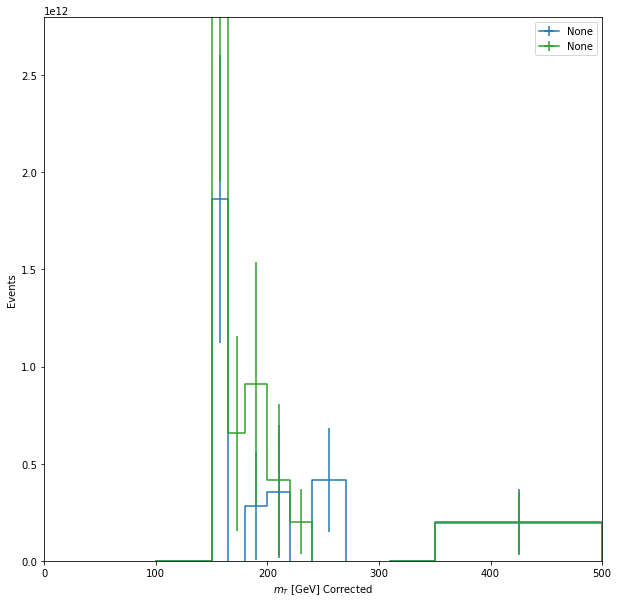

In [52]:
from coffea.hist import plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(10,10))
lines = []
line1 = plot.plot1d(histo.integrate('region', "wjete").integrate("systematic","METunclUp"),            
#         overlay="dataset",
        ax=ax,
        clear=False,
#             stack=True
           )

line2 = plot.plot1d(histo.integrate('region', "wjete").integrate("systematic","METunclDown"),            
#         overlay="dataset",
        ax=ax,
        clear=False
#             stack=True, 
           )
# line3 = plot.plot1d(histo.integrate('region', "wjete").integrate("systematic","nominal"),            
# #         overlay="dataset",
#         ax=ax,
#         clear=False,
# #             stack=True
#            )


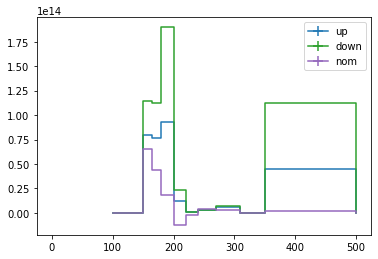

In [136]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep

bins = bins
up = up
down = down
nom = nom
f, ax = plt.subplots()
hep.histplot(up, bins, yerr=True,
label="up")
hep.histplot(down, bins, yerr=True,
label="down")
hep.histplot(nom, bins, yerr=True,
label="nom")
ax.legend()

In [87]:
down = histo.integrate('region', "wjete").integrate("systematic","pileupDown").values()[()]
nom = histo.integrate('region', "wjete").integrate("systematic","nominal").values()[()]
up = histo.integrate('region', "wjete").integrate("systematic","pileupUp").values()[()]

In [88]:
nom

array([ 0.00000000e+00,  0.00000000e+00,  6.53585373e+13,  4.38491395e+13,
        1.88327893e+13, -1.22441962e+13, -2.11423570e+12,  4.37315089e+12,
        2.83769156e+12,  0.00000000e+00,  2.02598413e+12])

In [89]:
up

array([0.00000000e+00, 0.00000000e+00, 8.00346614e+13, 7.67392524e+13,
       9.32426615e+13, 1.19725424e+13, 8.73868507e+11, 2.76714037e+12,
       5.60996158e+12, 0.00000000e+00, 4.47249891e+13])

In [90]:
down

array([0.00000000e+00, 0.00000000e+00, 1.14880102e+14, 1.12575954e+14,
       1.89746392e+14, 2.30082949e+13, 1.10203667e+12, 2.82861171e+12,
       6.72532304e+12, 0.00000000e+00, 1.12475714e+14])

In [31]:
corrections = util.load('../../data/corrections.coffea')
get_pu_nom_weight = corrections['get_pu_nom_weight_postVFP']['2017']
get_pu_up_weight = corrections['get_pu_up_weight_postVFP']['2017']
get_pu_down_weight = corrections['get_pu_down_weight_postVFP']['2017']

In [32]:
np.random.seed(0)
arr = np.linspace(0,100,101)

In [33]:
nom=get_pu_nom_weight(arr)

In [34]:
up=get_pu_up_weight(arr)

In [35]:
down=get_pu_down_weight(arr)

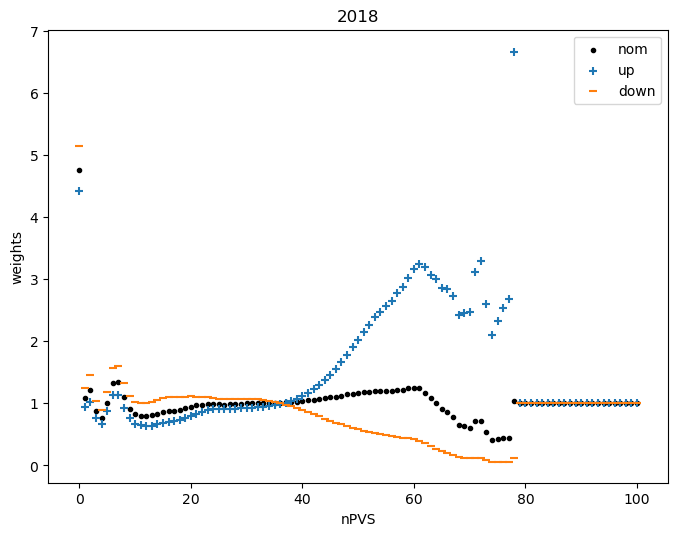

In [30]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

figure(figsize=(8, 6), dpi=100)
plt.scatter(arr, nom, marker='.', label="nom", color='black')
plt.scatter(arr, up, marker="+", label="up")
plt.scatter(arr, down, marker='_', label='down')
plt.legend()
plt.xlabel("nPVS")
plt.ylabel("weights")
plt.title("2018")
plt.show()

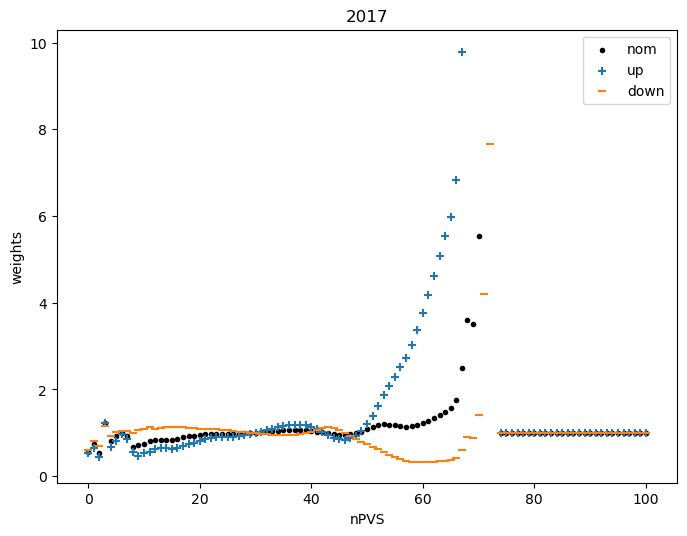

In [40]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

figure(figsize=(8, 6), dpi=100)
plt.scatter(arr[nom<10], nom[nom<10], marker='.', label="nom", color='black')
plt.scatter(arr[up<10], up[up<10], marker="+", label="up")
plt.scatter(arr[down<10], down[down<10], marker='_', label='down')
plt.legend()
plt.xlabel("nPVS")
plt.ylabel("weights")
plt.title("2017")
plt.show()

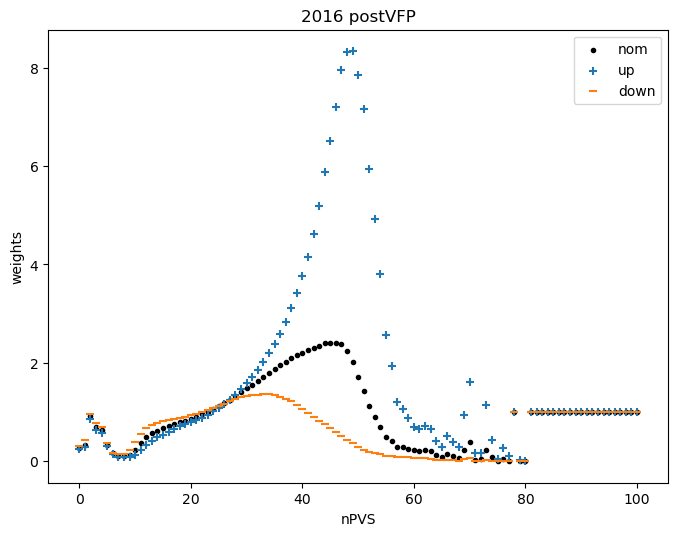

In [24]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

figure(figsize=(8, 6), dpi=100)
plt.scatter(arr, nom, marker='.', label="nom", color='black')
plt.scatter(arr, up, marker="+", label="up")
plt.scatter(arr, down, marker='_', label='down')
plt.legend()
plt.xlabel("nPVS")
plt.ylabel("weights")
plt.title("2016 postVFP")
plt.show()

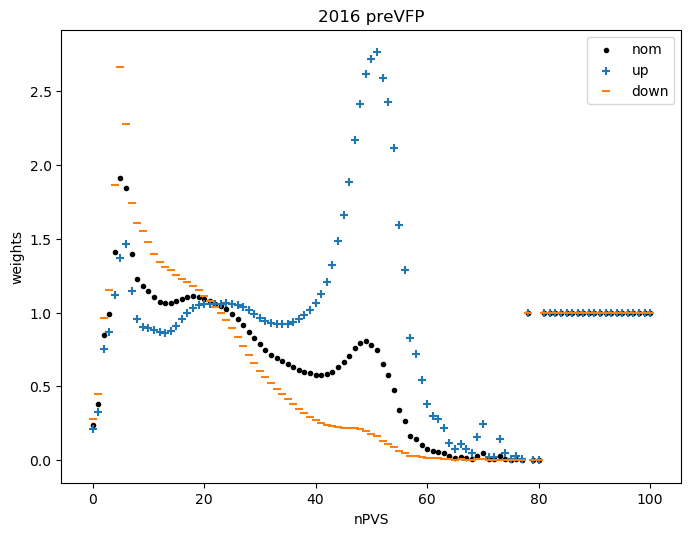

In [18]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

figure(figsize=(8, 6), dpi=100)
plt.scatter(arr, nom, marker='.', label="nom", color='black')
plt.scatter(arr, up, marker="+", label="up")
plt.scatter(arr, down, marker='_', label='down')
plt.legend()
plt.xlabel("nPVS")
plt.ylabel("weights")
plt.title("2016 preVFP")
plt.show()

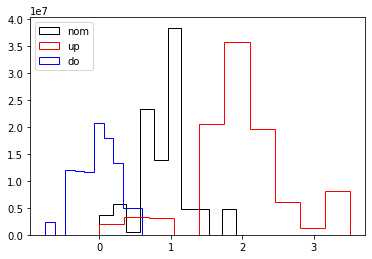

In [147]:
plt.hist(arr*nom, color='black', histtype='step', label='nom')
plt.hist(arr*(nom+up), color='red', histtype='step', label='up')
plt.hist(arr(nom-down), color='blue', histtype='step', label='do')
plt.legend()

In [152]:
arr.astype(int)

array([57, 28, 40, ..., 26, 25,  5])

(array([17., 16., 12., 14., 14.,  9.,  6.,  5.,  5.,  2.]),
 array([ 0. ,  6.7, 13.4, 20.1, 26.8, 33.5, 40.2, 46.9, 53.6, 60.3, 67. ]),
 <a list of 10 Patch objects>)

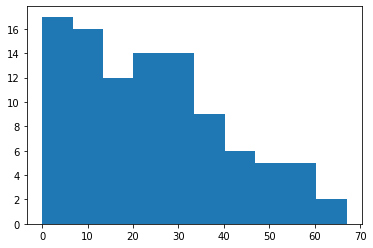

In [232]:
plt.hist(arr)

In [260]:
lst = ['a', 'b']

In [261]:
lst.extend(["c", "d"])

In [262]:
lst

['a', 'b', 'c', 'd']

In [67]:
dataset = "WZ_TuneCP5_13TeV-pythia8____1_"
if re.search("^W[WZ]_", dataset):
    print("hi")

hi


In [20]:
!xrdfs cmseos.fnal.gov ls /store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-995_Mchi-500_2018

/store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-995_Mchi-500_2018/Mphi-995_Mchi-500_2018_1.root
/store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-995_Mchi-500_2018/Mphi-995_Mchi-500_2018_2.root
/store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-995_Mchi-500_2018/Mphi-995_Mchi-500_2018_3.root
/store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-995_Mchi-500_2018/Mphi-995_Mchi-500_2018_4.root
/store/group/lpcmetx/Monotop/CustomNanoProdV9/2018/Mphi-995_Mchi-500_2018/Mphi-995_Mchi-500_2018_5.root


In [22]:
redirector = "root://cmseos.fnal.gov//store/group/lpcmetx/Monotop/CustomNanoProdV9/"
year_filecount = {"2016APV":6, "2016":6, "2017":5, "2018":5}
signals = ["Mphi-1000_Mchi-1000",
"Mphi-1000_Mchi-150",
"Mphi-1250_Mchi-150",
"Mphi-1495_Mchi-750",
"Mphi-1500_Mchi-1000",
"Mphi-1500_Mchi-150",
"Mphi-1700_Mchi-800",
"Mphi-1750_Mchi-150",
"Mphi-1750_Mchi-700",
"Mphi-195_Mchi-100",
"Mphi-1995_Mchi-1000",
"Mphi-2000_Mchi-1500",
"Mphi-2000_Mchi-150",
"Mphi-2000_Mchi-500",
"Mphi-200_Mchi-150",
"Mphi-200_Mchi-50",
"Mphi-2495_Mchi-1250",
"Mphi-2500_Mchi-2000",
"Mphi-2500_Mchi-750",
"Mphi-295_Mchi-150",
"Mphi-2995_Mchi-1500",
"Mphi-3000_Mchi-1000",
"Mphi-3000_Mchi-2000",
"Mphi-300_Mchi-100",
"Mphi-300_Mchi-300",
"Mphi-495_Mchi-250",
"Mphi-500_Mchi-150",
"Mphi-500_Mchi-500",
"Mphi-750_Mchi-150",
"Mphi-995_Mchi-500",]


In [60]:
!pwd

/cms/scratch/runiyal/new_coffea/decaf/analysis/Rishabh_NB/new_coffea_nbs


In [73]:
import os
# if not os.path.exists('signals'):
#     os.makedirs('signals')
for year, nfile in year_filecount.items():
    
    if not os.path.exists('signals/'+year):
        os.makedirs('signals/'+year)
    if "APV" in year:
        y = year[:-3]
    else: y = year  
    for signal in signals:
        with open(os.path.join("signals", year, signal)+'.txt', mode = "w") as f:
            for nfile in range(1,nfile+1):
                str_ = redirector+year+'/'+signal+'_'+y+'/'+signal+'_'+y+'_'+str(nfile)+'.root'
#                 print(str_)
                f.write(str_+"\n")
        
#         print("{}{}/{}_{}_{}.root".format(redirector, year, signal, y, nfile))

In [30]:
s = "2016APV"

In [93]:
import os
# if not os.path.exists('signals'):
#     os.makedirs('signals')
for year, nfile in year_filecount.items():
    
#     if not os.path.exists('../../metadata/UL_/'+year):
#         os.makedirs('signals/'+year)
    VFP = None
    if "2016" in year:
        if "APV" in year:
            y = year[:-3]
            folder_name = "UL_"+y+'_preVFP'
            VFP='preVFP'
        else:
            folder_name = "UL_"+year+'_postVFP'
            VFP='postVFP'
    else: 
        y = year 
        VFP=""
        folder_name = "UL_"+year
    for signal in signals:
        
        with open(os.path.join("../../metadata", folder_name, signal)+VFP+'.txt', mode = "w") as f:
            for nfile in range(1,nfile+1):
                str_ = redirector+year+'/'+signal+'_'+y+'/'+signal+'_'+y+'_'+str(nfile)+'.root'
#                 print(str_)
                f.write(str_+"\n")
        
#         print("{}{}/{}_{}_{}.root".format(redirector, year, signal, y, nfile))

In [80]:
xs_dict={"Mphi-1000_Mchi-1000": 5.344e-05, 
"Mphi-1000_Mchi-150": 3.727e-01, 
"Mphi-1250_Mchi-150": 1.444e-01, 
"Mphi-1495_Mchi-750": 1.206e-02, 
"Mphi-1500_Mchi-1000": 1.071e-04, 
"Mphi-1500_Mchi-150": 6.213e-02, 
"Mphi-1700_Mchi-800": 1.890e-02, 
"Mphi-1750_Mchi-150": 2.879e-02, 
"Mphi-1750_Mchi-700": 2.263e-02, 
"Mphi-195_Mchi-100": 4.931e+00, 
"Mphi-1995_Mchi-1000": 2.655e-03, 
"Mphi-2000_Mchi-150": 1.414e-02, 
"Mphi-2000_Mchi-1500": 4.319e-06, 
"Mphi-2000_Mchi-500": 1.297e-02, 
"Mphi-200_Mchi-150": 2.533e-01, 
"Mphi-200_Mchi-50": 5.759e+01, 
"Mphi-2495_Mchi-1250": 6.786e-04, 
"Mphi-2500_Mchi-2000": 2.682e-07, 
"Mphi-2500_Mchi-750": 3.237e-03, 
"Mphi-295_Mchi-150": 2.373e+00, 
"Mphi-2995_Mchi-1500": 1.901e-04, 
"Mphi-3000_Mchi-1000": 8.935e-04, 
"Mphi-3000_Mchi-2000": 4.319e-07, 
"Mphi-300_Mchi-100": 1.896e+01, 
"Mphi-300_Mchi-300": 1.890e-02, 
"Mphi-495_Mchi-250": 7.040e-01, 
"Mphi-500_Mchi-150": 4.315e+00, 
"Mphi-500_Mchi-500": 2.262e-03, 
"Mphi-750_Mchi-150": 1.124e+00, 
"Mphi-995_Mchi-500": 7.102e-02, }

In [ ]:
Mphi-1995_Mchi-1000_2016:
    tags: ['nanoaodv2', 'mc', 'global', 'ul', '2016']
    dbs:
        /DYJetsToLL_0J_TuneCP5_13TeV-amcatnloFXFX-pythia8/RunIISummer20UL18NanoAODv2-106X_upgrade2016_realistic_v15_L1v1-v1/NANOAODSIM
    xs:           1.0
Mphi-2000_Mchi-1500_2016:
    tags: ['nanoaodv2', 'mc', 'global', 'ul', '2016']
    dbs:
        /DYJetsToLL_0J_TuneCP5_13TeV-amcatnloFXFX-pythia8/RunIISummer20UL18NanoAODv2-106X_upgrade2016_realistic_v15_L1v1-v1/NANOAODSIM
    xs:           1.0
Mphi-2000_Mchi-500_2016:
    tags: ['nanoaodv2', 'mc', 'global', 'ul', '2016']
    dbs:
        /DYJetsToLL_0J_TuneCP5_13TeV-amcatnloFXFX-pythia8/RunIISummer20UL18NanoAODv2-106X_upgrade2016_realistic_v15_L1v1-v1/NANOAODSIM
    xs:           1.0

In [85]:
for signal in signals:
    year='2016'
    print(signal,':')
    print("\txs:",xs_dict[signal])

Mphi-1000_Mchi-1000 :
	xs: 5.344e-05
Mphi-1000_Mchi-150 :
	xs: 0.3727
Mphi-1250_Mchi-150 :
	xs: 0.1444
Mphi-1495_Mchi-750 :
	xs: 0.01206
Mphi-1500_Mchi-1000 :
	xs: 0.0001071
Mphi-1500_Mchi-150 :
	xs: 0.06213
Mphi-1700_Mchi-800 :
	xs: 0.0189
Mphi-1750_Mchi-150 :
	xs: 0.02879
Mphi-1750_Mchi-700 :
	xs: 0.02263
Mphi-195_Mchi-100 :
	xs: 4.931
Mphi-1995_Mchi-1000 :
	xs: 0.002655
Mphi-2000_Mchi-1500 :
	xs: 4.319e-06
Mphi-2000_Mchi-150 :
	xs: 0.01414
Mphi-2000_Mchi-500 :
	xs: 0.01297
Mphi-200_Mchi-150 :
	xs: 0.2533
Mphi-200_Mchi-50 :
	xs: 57.59
Mphi-2495_Mchi-1250 :
	xs: 0.0006786
Mphi-2500_Mchi-2000 :
	xs: 2.682e-07
Mphi-2500_Mchi-750 :
	xs: 0.003237
Mphi-295_Mchi-150 :
	xs: 2.373
Mphi-2995_Mchi-1500 :
	xs: 0.0001901
Mphi-3000_Mchi-1000 :
	xs: 0.0008935
Mphi-3000_Mchi-2000 :
	xs: 4.319e-07
Mphi-300_Mchi-100 :
	xs: 18.96
Mphi-300_Mchi-300 :
	xs: 0.0189
Mphi-495_Mchi-250 :
	xs: 0.704
Mphi-500_Mchi-150 :
	xs: 4.315
Mphi-500_Mchi-500 :
	xs: 0.002262
Mphi-750_Mchi-150 :
	xs: 1.124
Mphi-995_Mchi-50

In [87]:
import uproot
import json
import pyxrootd.client
import fnmatch
import numpy as np
import numexpr
import subprocess
import concurrent.futures
import warnings
import os
import difflib
from optparse import OptionParser
import glob
import yaml
import sys

In [88]:
yml_file = {}
yml_file['2016'] = '../../UL_data_processing/dataset_yml_files/MonoTop_UL_2016.yml'
yml_file['2017'] = '../../UL_data_processing/dataset_yml_files/MonoTop_UL_2017.yml'
yml_file['2018'] = '../../UL_data_processing/dataset_yml_files/MonoTop_UL_2018.yml'
with open(yml_file[year], 'r') as file:
    data = yaml.safe_load(file)
lst = list(data[year].keys())

xs_reference = {}
for dataset in lst:
#     print(dataset,':',data['2018'][dataset]['xs'])
    if 'EGamma' in dataset or 'SingleMuon' in dataset or 'MET' in dataset or 'SingleElectron' in dataset or 'SinglePhoton' in dataset:
        xs_reference[dataset] = -1
    else:    
        xs_reference[dataset] = data[year][dataset]['xs']

In [89]:
xs_reference

{'DYJetsToLL_0J_TuneCP5_13TeV-amcatnloFXFX-pythia8': 5125.0,
 'Mphi-1000_Mchi-1000': 5.344e-05,
 'Mphi-1000_Mchi-150': 0.3727,
 'Mphi-1250_Mchi-150': 0.1444,
 'Mphi-1495_Mchi-750': 0.01206,
 'Mphi-1500_Mchi-1000': 0.0001071,
 'Mphi-1500_Mchi-150': 0.06213,
 'Mphi-1700_Mchi-800': 0.0189,
 'Mphi-1750_Mchi-150': 0.02879,
 'Mphi-1750_Mchi-700': 0.02263,
 'Mphi-195_Mchi-100': 4.931,
 'Mphi-1995_Mchi-1000': 0.002655,
 'Mphi-2000_Mchi-1500': 4.319e-06,
 'Mphi-2000_Mchi-150': 0.01414,
 'Mphi-2000_Mchi-500': 0.01297,
 'Mphi-200_Mchi-150': 0.2533,
 'Mphi-200_Mchi-50': 57.59,
 'Mphi-2495_Mchi-1250': 0.0006786,
 'Mphi-2500_Mchi-2000': 2.682e-07,
 'Mphi-2500_Mchi-750': 0.003237,
 'Mphi-295_Mchi-150': 2.373,
 'Mphi-2995_Mchi-1500': 0.0001901,
 'Mphi-3000_Mchi-1000': 0.0008935,
 'Mphi-3000_Mchi-2000': 4.319e-07,
 'Mphi-300_Mchi-100': 18.96,
 'Mphi-300_Mchi-300': 0.0189,
 'Mphi-495_Mchi-250': 0.704,
 'Mphi-500_Mchi-150': 4.315,
 'Mphi-500_Mchi-500': 0.002262,
 'Mphi-750_Mchi-150': 1.124,
 'Mphi-995_Mc